# Ames Mutagenicity: Classical and Graph Neural Network Models

## Part 6 — Figures and tables

Every figure and every table in the manuscript is produced here from the stored results, so
that no quantity reported in the text is entered by hand. The notebook reads only the CSV
and NPZ files written by Parts 1 to 5 and writes to `figures/` and `tables/`.

A companion file, `tables/manuscript_numbers.csv`, records each quantity quoted in the text
together with its value, so that any number in the manuscript can be traced to the analysis
that produced it.

**Contents**

1. Environment
2. Shared figure style
3. Figure modules
4. Table module
5. Generate figures and tables
6. Removing exact duplicates
7. Qualitative attribution examples

*Approximate runtime: about ten minutes, most of it in the final section, which loads the trained model to draw attributions on individual molecules. No GPU required.*

## 1. Environment

In [1]:
!pip install -q matplotlib pandas scipy
!pip install -q rdkit
!pip install -q xgboost
!pip install -q shap
!pip install -q torch_geometric

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 36.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 2.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 23.7 MB/s eta 0:00:00


In [2]:
from google.colab import drive
drive.mount('/content/drive')

import os
WORK   = "/content/drive/MyDrive/ames_pipeline"
R      = f"{WORK}/results"
FIGDIR = f"{WORK}/figures"
TABDIR = f"{WORK}/tables"
DATADIR = f"{WORK}/data"
MODELS = f"{WORK}/models"
EXPL   = f"{WORK}/explain"
os.makedirs(FIGDIR, exist_ok=True); os.makedirs(TABDIR, exist_ok=True)
print("Results:", R)

Mounted at /content/drive
Results: /content/drive/MyDrive/ames_pipeline/results


## 2. Shared figure style

One palette and one set of typographic settings are used throughout. Classical models are
drawn in blues and graph models in warm tones, so that family membership is legible without
consulting the legend.

In [3]:
%%writefile /content/figstyle.py
"""Shared figure style for the Ames mutagenicity study."""
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np, pandas as pd

plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 8.5,
    "axes.labelsize": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold",
    "xtick.labelsize": 7.5, "ytick.labelsize": 7.5, "legend.fontsize": 7.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.linewidth": .7, "xtick.major.width": .7, "ytick.major.width": .7,
    "xtick.major.size": 3, "ytick.major.size": 3,
    "figure.dpi": 200, "savefig.dpi": 400, "savefig.bbox": "tight",
    "legend.frameon": False, "lines.linewidth": 1.3,
})

CLASSICAL = "#2166ac"
GRAPH     = "#b2182b"
COL = {"XGBoost": "#0b3d68", "RandomForest": "#2166ac", "XGBoost_RDKit2D": "#8ec4e0",
       "GCN": "#d6604d", "GIN": "#e08214", "GAT": "#8c1c13"}
SHORT = {"XGBoost": "XGB\nECFP4", "RandomForest": "RF\nECFP4",
         "XGBoost_RDKit2D": "XGB\nRDKit-2D", "GCN": "GCN", "GIN": "GIN", "GAT": "GAT"}
FLAT  = {"XGBoost": "XGB · ECFP4", "RandomForest": "RF · ECFP4",
         "XGBoost_RDKit2D": "XGB · RDKit-2D", "GCN": "GCN", "GIN": "GIN", "GAT": "GAT"}
FAMILY = {"XGBoost": "classical", "RandomForest": "classical",
          "XGBoost_RDKit2D": "classical", "GCN": "graph", "GIN": "graph", "GAT": "graph"}

def panel(ax, letter, title, pad=1.0):
    ax.set_title(f"({letter}) {title}", loc="left", pad=6)

def save(fig, outdir, name):
    for ext in ("png", "pdf"):
        fig.savefig(f"{outdir}/{name}.{ext}")
    plt.close(fig)


Writing /content/figstyle.py


## 3. Figure modules

Each module exposes a `build(R, F)` function that reads the results directory and writes one
figure in both raster and vector form.

*Study design, molecule flow and the control protocol.*

In [4]:
%%writefile /content/fig_schematics.py
from figstyle import *
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch

def _box(ax, x, y, w, h, text, fc="white", ec="0.35", fs=6.8, lw=.9, tc="0.15"):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.006,rounding_size=0.012",
                                fc=fc, ec=ec, lw=lw, zorder=2))
    ax.text(x + w/2, y + h/2, text, ha="center", va="center", fontsize=fs,
            zorder=3, color=tc, linespacing=1.35)

def _arrow(ax, p, q, ec="0.45", lw=.9, style="-|>"):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle=style, mutation_scale=8,
                                 color=ec, lw=lw, zorder=1,
                                 shrinkA=1, shrinkB=1))

def _blank(ax):
    ax.set_xlim(0, 1); ax.set_ylim(0, 1); ax.axis("off")

# ---------------------------------------------------------------- pipeline
def pipeline(R, F):
    d = pd.read_csv(f"{R}/data_summary.csv").set_index("metric")["value"]
    hpo = pd.read_csv(f"{R}/hpo_budget.csv")
    fig, ax = plt.subplots(figsize=(7.1, 3.5)); _blank(ax)
    _box(ax, .02, .78, .21, .15, f"TDC Ames benchmark\n{int(d['n_total']):,} compounds",
         fc="#eef3f8")
    _box(ax, .02, .56, .21, .15, "Canonicalisation\nand curation", fc="#eef3f8")
    _arrow(ax, (.125, .78), (.125, .71))
    _box(ax, .02, .30, .21, .20,
         "Partitions\n15 scaffold · 15 random\n1 primary (disjoint)", fc="#eef3f8")
    _arrow(ax, (.125, .56), (.125, .50))
    _box(ax, .30, .62, .22, .18,
         "Circular fingerprints\nRDKit-2D descriptors", fc="#dce9f5")
    _box(ax, .30, .34, .22, .18, "Molecular graphs\natom and bond features", fc="#f7e0d0")
    _arrow(ax, (.23, .43), (.30, .68)); _arrow(ax, (.23, .38), (.30, .44))
    _box(ax, .585, .62, .22, .18,
         "XGBoost · Random forest\nlogistic regression", fc="#dce9f5")
    _box(ax, .585, .34, .22, .18, "GCN · GIN · GAT\n(+ bond-feature ablation)", fc="#f7e0d0")
    _arrow(ax, (.52, .71), (.585, .71)); _arrow(ax, (.52, .43), (.585, .43))
    n = int(hpo.n_trials.iloc[0]) if len(hpo) else 100
    ax.text(.6975, .225, f"identical search budget: {n} trials per model,\n"
            "one training protocol for search and final fits",
            ha="center", fontsize=6.4, color="0.4", style="italic")
    for i, (lab, col) in enumerate([("Accuracy", "#eef3f8"), ("Calibration", "#eef3f8"),
                                    ("Explanation", "#eef3f8")]):
        _box(ax, .30 + i*.185, .10, .17, .10, lab, fc=col)
        _arrow(ax, (.6975, .34), (.385 + i*.185, .20))
    _box(ax, .855, .10, .13, .10, "Negative\ncontrols", fc="#f2e3ef")
    _arrow(ax, (.845, .15), (.855, .15))
    ax.text(.5, .965, "Study design", ha="center", fontsize=8.5, weight="bold")
    save(fig, F, "fig01_pipeline")

# ------------------------------------------------------------ molecule flow
def molecule_flow(R, F):
    d = pd.read_csv(f"{R}/data_summary.csv").set_index("metric")["value"]
    te = pd.read_csv(f"{R}/primary_test.csv")
    expl = pd.read_csv(f"{R}/table11_explainers.csv")
    auc = pd.read_csv(f"{R}/table19_attribution_significance.csv")
    n_eval = int(expl.n.iloc[0])
    fid = pd.read_csv(f"{R}/table11b_fidelity_removal.csv")
    n_fid = int(fid.n_fidelity.max())
    n_test, n_pos = len(te), int(te.label.sum())

    fig, ax = plt.subplots(figsize=(4.6, 4.3)); _blank(ax)
    steps = [(f"Curated compounds\n$n$ = {int(d['n_total']):,}", ""),
             (f"Primary test partition\n$n$ = {n_test}", "80/10/10 scaffold split"),
             (f"Mutagenic test compounds\n$n$ = {n_pos}", "label = 1"),
             (f"Carrying $\\geq$ 1 toxicophore\n$n$ = {n_eval}",
              "evaluation set for all\nattribution comparisons"),
             (f"Correctly classified by the\nrepresentative GIN   $n$ = {n_fid}",
              "subset used for the\nfidelity comparison")]
    h, gap = .125, .068
    y = .825
    for i, (main, note) in enumerate(steps):
        _box(ax, .06, y, .60, h, main, fc="#eef3f8" if i < 3 else "#f7e0d0", fs=7)
        if note:
            ax.text(.70, y + h/2, note, fontsize=6.1, color="0.45", va="center",
                    linespacing=1.3)
        if i < len(steps) - 1:
            _arrow(ax, (.36, y), (.36, y - gap))
        y -= h + gap
    ax.text(.5, .965, "Molecules entering each analysis", ha="center",
            fontsize=8.5, weight="bold")
    save(fig, F, "fig11_molecule_flow")

# --------------------------------------------------------------- protocol
def protocol(R, F):
    tg = pd.read_csv(f"{R}/table13_training_gain.csv").iloc[0]
    fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.9)); [_blank(a) for a in ax]
    a, b = ax
    a.text(.5, .95, "(a) Common practice", ha="center", fontsize=8.5, weight="bold")
    _box(a, .18, .70, .64, .13, "one untrained model", fc="#f0f0f0")
    _arrow(a, (.5, .70), (.5, .62))
    _box(a, .18, .47, .64, .13, "one attribution score", fc="#f0f0f0")
    _arrow(a, (.5, .47), (.5, .39))
    _box(a, .18, .24, .64, .13, "compared by eye with\nthe trained model", fc="#f0f0f0")
    a.text(.5, .12, "a single draw carries no\nstatement about variability",
           ha="center", fontsize=6.5, color="#8c1c13", style="italic")

    b.text(.5, .95, "(b) Protocol adopted here", ha="center", fontsize=8.5, weight="bold")
    _box(b, .05, .70, .40, .13, f"{int(tg.n_untrained)} untrained\ninitialisations",
         fc="#e8eef6")
    _box(b, .55, .70, .40, .13, f"{int(tg.n_trained)} independently\ntrained models",
         fc="#fbe8d5")
    _arrow(b, (.25, .70), (.25, .60)); _arrow(b, (.75, .70), (.75, .60))
    _box(b, .05, .45, .40, .13, "empirical null\ndistribution", fc="#e8eef6")
    _box(b, .55, .45, .40, .13, "distribution of\ntrained scores", fc="#fbe8d5")
    _arrow(b, (.25, .45), (.42, .34)); _arrow(b, (.75, .45), (.58, .34))
    _box(b, .12, .19, .76, .14,
         "molecule-level paired test\nwith interval and effect size", fc="#f2e3ef")
    b.text(.5, .07, f"training adds {tg.lift_difference_aggregate:+.3f} lift  "
           f"(95% CI {tg.diff_ci_low:+.3f} to {tg.diff_ci_high:+.3f})",
           ha="center", fontsize=6.5, color="0.3", style="italic")
    save(fig, F, "fig12_protocol")


Writing /content/fig_schematics.py


*Predictive performance across the scaffold partitions.*

In [5]:
%%writefile /content/fig_benchmark.py
from figstyle import *
from scipy.stats import friedmanchisquare, rankdata, wilcoxon

def build(R, F):
    piv = pd.read_csv(f"{R}/table25_six_model_benchmark.csv", index_col=0)
    order = piv.mean().sort_values().index.tolist()      # worst -> best, bottom-up
    N, k = piv.shape
    stat, p = friedmanchisquare(*[piv[c].values for c in order])
    CD = 2.850 * np.sqrt(k * (k + 1) / (6 * N))
    ranks = pd.Series(np.mean([rankdata(-r) for r in piv[order].values], axis=0),
                      index=order)

    fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.9), sharey=True,
                           gridspec_kw={"width_ratios": [1.5, 1], "wspace": .08})
    y = np.arange(len(order))
    rng = np.random.default_rng(0)

    a = ax[0]
    for i, m in enumerate(order):
        v = piv[m].values
        a.scatter(v, rng.normal(i, .075, len(v)), s=13, color=COL[m],
                  alpha=.5, edgecolors="none", zorder=3)
        a.vlines(v.mean(), i - .28, i + .28, color=COL[m], lw=2.4, zorder=4)
        a.hlines(i, v.mean() - v.std(ddof=1), v.mean() + v.std(ddof=1),
                 color=COL[m], lw=1.0, zorder=4)
    a.set_yticks(y)
    a.set_yticklabels([FLAT[m] for m in order])
    a.set_xlabel("ROC-AUC on held-out scaffolds")
    panel(a, "a", f"Fifteen scaffold partitions")
    a.grid(axis="x", alpha=.22, lw=.5); a.set_axisbelow(True)
    a.set_ylim(-.6, len(order) - .4)
    a.text(.985, .045, f"Friedman $\\chi^2$ = {stat:.1f},  $p$ = {p:.0e}",
           transform=a.transAxes, fontsize=7, style="italic", color="0.35", ha="right")

    b = ax[1]
    b.barh(y, [ranks[m] for m in order], color=[COL[m] for m in order],
           height=.55, zorder=3)
    best = ranks.min()
    b.axvspan(best, best + CD, color="0.88", zorder=0)
    b.axvline(best + CD, color="0.5", lw=.9, ls=(0, (4, 2)), zorder=2)
    for i, m in enumerate(order):
        b.text(ranks[m] + .13, i, f"{ranks[m]:.2f}", va="center",
               fontsize=7, color="0.3")
    b.set_xlabel("Mean rank")
    panel(b, "b", "Mean rank")
    b.set_xlim(0, 6.9)
    b.grid(axis="x", alpha=.22, lw=.5); b.set_axisbelow(True)
    b.annotate(f"critical difference = {CD:.2f}",
               xy=(best + CD, len(order) - .55), xytext=(best + CD + .25, len(order) - .75),
               fontsize=6.8, color="0.4", style="italic",
               arrowprops=dict(arrowstyle="-", color="0.6", lw=.6))

    save(fig, F, "fig02_benchmark")
    return {"friedman_chi2": stat, "friedman_p": p, "critical_difference": CD,
            **{f"mean_rank_{m}": ranks[m] for m in order},
            **{f"mean_auc_{m}": piv[m].mean() for m in order}}


Writing /content/fig_benchmark.py


*Representation, learner and family contributions.*

In [6]:
%%writefile /content/fig_effects.py
from figstyle import *
from scipy.stats import wilcoxon, rankdata

def paired(a, b):
    d = np.asarray(a) - np.asarray(b)
    nz = d[d != 0]; rk = rankdata(np.abs(nz))
    rb = (rk[nz > 0].sum() - rk[nz < 0].sum()) / (rk[nz > 0].sum() + rk[nz < 0].sum())
    return d.mean(), wilcoxon(d)[1], rb, int((d > 0).sum()), len(d)

def build(R, F):
    piv = pd.read_csv(f"{R}/table25_six_model_benchmark.csv", index_col=0)
    rng = np.random.default_rng(0)
    comparisons = [
        ("Representation\nXGB: ECFP4 $\\rightarrow$ RDKit-2D",
         piv["XGBoost_RDKit2D"], piv["XGBoost"], CLASSICAL),
        ("Learner\nECFP4: XGB $\\rightarrow$ RF",
         piv["RandomForest"], piv["XGBoost"], CLASSICAL),
        ("Model family\ngraph $\\rightarrow$ classical mean",
         piv[["GCN", "GIN", "GAT"]].mean(axis=1),
         piv[["XGBoost", "RandomForest", "XGBoost_RDKit2D"]].mean(axis=1), GRAPH),
        ("Best of each family\nGIN $\\rightarrow$ XGB RDKit-2D",
         piv["GIN"], piv["XGBoost_RDKit2D"], "0.35"),
    ]
    fig, ax = plt.subplots(figsize=(3.42, 2.9))
    rows = []
    for i, (lab, a, b, col) in enumerate(comparisons[::-1]):
        m, p, rb, w, n = paired(a, b)
        d = np.asarray(a) - np.asarray(b)
        boot = np.array([d[rng.integers(0, n, n)].mean() for _ in range(10000)])
        lo, hi = np.percentile(boot, [2.5, 97.5])
        ax.errorbar(m, i, xerr=[[m - lo], [hi - m]], fmt="o", ms=4.5, color=col,
                    capsize=3, lw=1.4, zorder=3)
        ptxt = "$p$ < 0.001" if p < 0.001 else f"$p$ = {p:.3f}"
        ax.text(hi + .0016, i, f"{ptxt}   {w}/{n}", va="center",
                fontsize=5.8, color="0.35")
        rows.append({"comparison": lab.replace("\n", " "), "mean_difference": m,
                     "ci_low": lo, "ci_high": hi, "wilcoxon_p": p,
                     "rank_biserial": rb, "n_favourable": w, "n_partitions": n})
    ax.axvline(0, color="0.6", lw=.8, ls=(0, (4, 2)), zorder=1)
    ax.set_yticks(range(len(comparisons)))
    ax.set_yticklabels([c[0] for c in comparisons[::-1]], fontsize=6.2)
    ax.set_xlabel("Paired difference in ROC-AUC across 15 scaffold partitions")
    ax.set_xlim(-.008, .045)
    ax.grid(axis="x", alpha=.22, lw=.5); ax.set_axisbelow(True)
    save(fig, F, "fig03_effect_decomposition")
    return pd.DataFrame(rows[::-1])


Writing /content/fig_effects.py


*Dependence of the ranking on the evaluation metric.*

In [7]:
%%writefile /content/fig_metrics.py
from figstyle import *
from scipy.stats import rankdata

def build(R, F):
    runs = pd.read_csv(f"{R}/benchmark_runs.csv")
    sc = runs[(runs.scheme == "scaffold") & (runs.arm == "main")]
    desc = pd.read_csv(f"{R}/benchmark_runs_descriptor.csv")
    metrics = [("ROC_AUC", "ROC-AUC", True), ("PR_AUC", "PR-AUC", True),
               ("balanced_acc", "Balanced\naccuracy", True),
               ("sensitivity", "Sensitivity", True),
               ("specificity", "Specificity", True), ("MCC", "MCC", True)]
    models = ["XGBoost", "RandomForest", "XGBoost_RDKit2D", "GCN", "GIN", "GAT"]
    M = np.zeros((len(models), len(metrics)))
    for j, (col, _, hi) in enumerate(metrics):
        piv = sc.pivot_table(index="partition", columns="model", values=col)
        if col in desc.columns:
            piv["XGBoost_RDKit2D"] = desc.set_index("partition")[col]
        else:
            piv["XGBoost_RDKit2D"] = np.nan
        piv = piv[models]
        if piv["XGBoost_RDKit2D"].isna().all():
            M[:, j] = np.nan; continue
        sign = -1 if hi else 1
        M[:, j] = np.nanmean([rankdata(sign * r) for r in piv.dropna().values], axis=0)

    fig, ax = plt.subplots(figsize=(3.42, 2.9))
    im = ax.imshow(M, cmap="RdYlBu_r", vmin=1, vmax=6, aspect="auto")
    for i in range(len(models)):
        for j in range(len(metrics)):
            if np.isnan(M[i, j]):
                ax.text(j, i, "–", ha="center", va="center", fontsize=6, color="0.5")
            else:
                ax.text(j, i, f"{M[i, j]:.1f}", ha="center", va="center", fontsize=6,
                        color="white" if (M[i, j] < 2.2 or M[i, j] > 4.8) else "0.15")
    ax.set_xticks(range(len(metrics)))
    ax.set_xticklabels([m[1] for m in metrics], fontsize=6, rotation=32, ha="right")
    ax.set_yticks(range(len(models)))
    ax.set_yticklabels([FLAT[m] for m in models], fontsize=6.4)
    ax.set_title("Mean rank across fifteen scaffold partitions", loc="left", pad=6)
    cb = fig.colorbar(im, ax=ax, fraction=.035, pad=.03)
    cb.set_label("rank (1 = best)", fontsize=7); cb.ax.tick_params(labelsize=6.5)
    ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)
    save(fig, F, "fig04_metric_dependence")
    return pd.DataFrame(M, index=models, columns=[m[0] for m in metrics])


Writing /content/fig_metrics.py


*Cost of random rather than scaffold partitioning.*

In [8]:
%%writefile /content/fig_partition.py
from figstyle import *
from scipy.stats import wilcoxon

def build(R, F):
    runs = pd.read_csv(f"{R}/benchmark_runs.csv")
    main = runs[runs.arm == "main"]
    d_sc = pd.read_csv(f"{R}/benchmark_runs_descriptor.csv")
    d_rn = pd.read_csv(f"{R}/benchmark_runs_descriptor_random.csv")
    models = ["XGBoost", "RandomForest", "XGBoost_RDKit2D", "GCN", "GIN", "GAT"]

    sc, rn = {}, {}
    for m in models[:2] + models[3:]:
        sc[m] = main[(main.scheme == "scaffold") & (main.model == m)].ROC_AUC.values
        rn[m] = main[(main.scheme == "random") & (main.model == m)].ROC_AUC.values
    sc["XGBoost_RDKit2D"] = d_sc.ROC_AUC.values
    rn["XGBoost_RDKit2D"] = d_rn.ROC_AUC.values

    fig, ax = plt.subplots(1, 2, figsize=(7.1, 3.0),
                           gridspec_kw={"width_ratios": [1.15, 1], "wspace": .42})
    a = ax[0]
    for i, m in enumerate(models):
        a.scatter(np.full(len(sc[m]), i - .17), sc[m], s=11, color=COL[m],
                  alpha=.45, edgecolors="none")
        a.scatter(np.full(len(rn[m]), i + .17), rn[m], s=11, color=COL[m],
                  alpha=.45, edgecolors="none", marker="s")
        a.plot([i - .17, i + .17], [np.mean(sc[m]), np.mean(rn[m])],
               color=COL[m], lw=1.6, marker="o", ms=4, zorder=4)
    a.set_xticks(range(len(models)))
    a.set_xticklabels([SHORT[m] for m in models], fontsize=6.8)
    a.set_ylabel("ROC-AUC")
    panel(a, "a", "Scaffold vs. random partitions")
    a.grid(axis="y", alpha=.22, lw=.5); a.set_axisbelow(True)

    b = ax[1]
    infl = {m: np.mean(rn[m]) - np.mean(sc[m]) for m in models}
    y = np.arange(len(models))[::-1]
    b.barh(y, [infl[m] for m in models], color=[COL[m] for m in models], height=.55)
    for yy, m in zip(y, models):
        b.text(infl[m] + .002, yy, f"+{infl[m]:.3f}", va="center", fontsize=7,
               color="0.3")
    b.set_yticks(y); b.set_yticklabels([FLAT[m] for m in models], fontsize=7)
    b.set_xlabel("$\\Delta$ ROC-AUC, random $-$ scaffold")
    panel(b, "b", "Inflation")
    b.set_xlim(0, .145)
    b.grid(axis="x", alpha=.22, lw=.5); b.set_axisbelow(True)
    save(fig, F, "fig05_partition_scheme")
    return pd.DataFrame({"model": models,
                         "scaffold_mean": [np.mean(sc[m]) for m in models],
                         "random_mean": [np.mean(rn[m]) for m in models],
                         "inflation": [infl[m] for m in models]})


Writing /content/fig_partition.py


*Fitted temperatures and reliability.*

In [9]:
%%writefile /content/fig_calibration.py
from figstyle import *

def build(R, F):
    runs = pd.read_csv(f"{R}/benchmark_runs.csv")
    sc = runs[(runs.scheme == "scaffold") & (runs.arm == "main")]
    models = ["XGBoost", "RandomForest", "GCN", "GIN", "GAT"]
    z = np.load(f"{R}/predictions_primary.npz")
    y = z["y_test"]

    fig, ax = plt.subplots(1, 2, figsize=(7.1, 2.9),
                           gridspec_kw={"width_ratios": [1, 1.05], "wspace": .28})
    a = ax[0]
    rng = np.random.default_rng(0)
    for i, m in enumerate(models):
        v = sc[sc.model == m].temperature.values
        a.scatter(rng.normal(i, .07, len(v)), v, s=12, color=COL[m], alpha=.5,
                  edgecolors="none", zorder=3)
        a.hlines(v.mean(), i - .28, i + .28, color=COL[m], lw=2.3, zorder=4)
    a.axhline(1.0, color="0.45", lw=.9, ls=(0, (4, 2)), zorder=2)
    a.text(.03, 1.008, "calibrated", transform=a.get_yaxis_transform(),
           fontsize=6.8, color="0.45", va="bottom")
    a.set_xticks(range(len(models)))
    a.set_xticklabels([FLAT[m] for m in models], fontsize=7, rotation=18, ha="right")
    a.set_ylabel("Fitted temperature")
    panel(a, "a", "Temperature over fifteen partitions")
    a.grid(axis="y", alpha=.22, lw=.5); a.set_axisbelow(True)
    a.text(.98, .96, "overconfident", transform=a.transAxes, ha="right", fontsize=6.8,
           color="0.45", style="italic")
    a.text(.98, .04, "underconfident", transform=a.transAxes, ha="right", fontsize=6.8,
           color="0.45", style="italic")

    b = ax[1]
    b.plot([0, 1], [0, 1], color="0.6", lw=.9, ls=(0, (4, 2)), zorder=1)
    for m in models:
        p = z[f"test_{m}"]
        edges = np.quantile(p, np.linspace(0, 1, 9))
        xs, ys = [], []
        for lo, hi in zip(edges[:-1], edges[1:]):
            sel = (p >= lo) & (p <= hi)
            if sel.sum() > 10:
                xs.append(p[sel].mean()); ys.append(y[sel].mean())
        b.plot(xs, ys, marker="o", ms=3.4, color=COL[m], label=FLAT[m], lw=1.2)
    b.set_xlabel("Mean predicted probability")
    b.set_ylabel("Observed frequency")
    panel(b, "b", "Reliability, primary partition")
    b.legend(loc="upper left", fontsize=6.8, handlelength=1.4)
    b.grid(alpha=.22, lw=.5); b.set_axisbelow(True)
    save(fig, F, "fig06_calibration")
    return sc.groupby("model").temperature.agg(["mean", "std"]).reindex(models)


Writing /content/fig_calibration.py


*Toxicophore agreement against the controls.*

In [10]:
%%writefile /content/fig_attribution.py
from figstyle import *

ECOL = {"XGBoost (TreeSHAP, signed)": "#2166ac",
        "GIN (Integrated Gradients)": "#e08214",
        "GIN (Gradient x Input)":     "#f0a860",
        "GIN (Saliency)":             "#b5651d",
        "GIN (GNNExplainer)":         "#7b3294"}
ENAME = {"XGBoost (TreeSHAP, signed)": "TreeSHAP (XGBoost)",
         "GIN (Integrated Gradients)": "Integrated Gradients",
         "GIN (Gradient x Input)":     "Gradient $\\times$ Input",
         "GIN (Saliency)":             "Saliency",
         "GIN (GNNExplainer)":         "GNNExplainer"}

def build(R, F):
    t = pd.read_csv(f"{R}/table17_topk_sensitivity.csv")
    null = t[t.source.str.contains("untrained")].sort_values("k_fraction")
    fig, ax = plt.subplots(1, 2, figsize=(7.1, 3.15),
                           gridspec_kw={"width_ratios": [1.1, 1], "wspace": .3})

    a = ax[0]
    a.fill_between(null.k_fraction, null.null_p2_5, null.null_p97_5,
                   color="0.82", zorder=1,
                   label="untrained GIN, central 95%")
    a.plot(null.k_fraction, null.lift, color="0.35", lw=1.3, ls=(0, (4, 2)),
           zorder=2, label="untrained GIN, mean")
    for e in ECOL:
        s = t[t.source == e].sort_values("k_fraction")
        a.plot(s.k_fraction, s.lift, marker="o", ms=3.6, color=ECOL[e],
               label=ENAME[e], zorder=3)
    a.axhline(1.0, color="0.55", lw=.8, zorder=1)
    a.set_xlabel("Fraction of atoms retained")
    a.set_ylabel("Toxicophore lift over chance")
    panel(a, "a", "Agreement at every retained fraction")
    a.set_xticks([.1, .2, .3, .4, .5])
    a.grid(alpha=.22, lw=.5); a.set_axisbelow(True)
    a.legend(loc="upper right", fontsize=6.5, handlelength=1.5, ncol=1)

    b = ax[1]
    lift = pd.read_csv(f"{R}/table19b_lift_significance.csv")
    n12 = pd.read_csv(f"{R}/table12_untrained_null.csv")
    gin = n12[n12.arch == "gin"].iloc[0]
    drt = pd.read_csv(f"{R}/table14_label_permuted.csv")
    tg  = pd.read_csv(f"{R}/table13_training_gain.csv").iloc[0]

    items = [("TreeSHAP\n(XGBoost)", lift[lift.explainer.str.contains("TreeSHAP")].iloc[0], "#2166ac"),
             ("Integrated\nGradients", lift[lift.explainer.str.contains("Integrated")].iloc[0], "#e08214"),
             ("GNNExplainer", lift[lift.explainer.str.contains("GNNExplainer")].iloc[0], "#7b3294")]
    for i, (lab, r, c) in enumerate(items):
        b.bar(i, r.lift, color=c, width=.6, zorder=3)
        b.errorbar(i, r.lift, yerr=[[r.lift - r.lift_ci_low], [r.lift_ci_high - r.lift]],
                   fmt="none", ecolor="0.25", capsize=3, lw=1, zorder=4)
    xperm, xnull = 3, 4
    b.bar(xperm, drt[drt.arm == "graph"].lift.iloc[0], color="#c9a227", width=.6, zorder=3)
    b.bar(xnull, gin["mean"], color="0.55", width=.6, zorder=3)
    b.errorbar(xnull, gin["mean"], yerr=[[gin["mean"] - gin.p2_5], [gin.p97_5 - gin["mean"]]],
               fmt="none", ecolor="0.25", capsize=3, lw=1, zorder=4)
    b.axhspan(gin.p2_5, gin.p97_5, color="0.88", zorder=0)
    b.axhline(1.0, color="0.4", lw=.9, ls=(0, (4, 2)), zorder=2)
    b.set_xticks(range(5))
    b.set_xticklabels(["TreeSHAP\n(XGBoost)", "Integrated\nGradients", "GNN-\nExplainer",
                       "GIN\npermuted", "GIN\nuntrained"], fontsize=6.4,
                      rotation=32, ha="right")
    b.set_ylabel("Toxicophore lift over chance")
    panel(b, "b", "Trained models against their controls")
    b.set_ylim(.8, 1.75)
    b.grid(axis="y", alpha=.22, lw=.5); b.set_axisbelow(True)
    b.text(.98, .95, "shaded: central 95% of\nuntrained initialisations",
           transform=b.transAxes, ha="right", va="top", fontsize=6.3, color="0.4")
    save(fig, F, "fig07_attribution")
    return t.pivot_table(index="source", columns="k_fraction", values="lift")


Writing /content/fig_attribution.py


*Comparison of attribution methods.*

In [11]:
%%writefile /content/fig_explainers.py
from figstyle import *

def build(R, F):
    lift = pd.read_csv(f"{R}/table19b_lift_significance.csv")
    auc  = pd.read_csv(f"{R}/table19_attribution_significance.csv")
    fid  = pd.read_csv(f"{R}/table11b_fidelity_removal.csv")
    stab = pd.read_csv(f"{R}/table16_stability.csv")
    name = {"XGBoost (TreeSHAP, signed)": "TreeSHAP",
            "GIN (Integrated Gradients)": "IG",
            "GIN (Gradient x Input)": "Grad$\\times$Inp",
            "GIN (Saliency)": "Saliency",
            "GIN (GNNExplainer)": "GNNExpl."}
    col  = {"XGBoost (TreeSHAP, signed)": "#2166ac",
            "GIN (Integrated Gradients)": "#e08214",
            "GIN (Gradient x Input)": "#f0a860",
            "GIN (Saliency)": "#b5651d",
            "GIN (GNNExplainer)": "#7b3294"}
    order = list(name)
    fig, ax = plt.subplots(1, 3, figsize=(7.1, 2.75), gridspec_kw={"wspace": .42})

    a = ax[0]
    v = lift.set_index("explainer").reindex(order)
    a.bar(range(5), v.lift, color=[col[m] for m in order], width=.62, zorder=3)
    a.errorbar(range(5), v.lift,
               yerr=[v.lift - v.lift_ci_low, v.lift_ci_high - v.lift],
               fmt="none", ecolor="0.25", capsize=2.5, lw=.9, zorder=4)
    a.axhline(1, color="0.4", lw=.9, ls=(0, (4, 2)))
    a.set_ylabel("Toxicophore lift"); a.set_ylim(.8, 1.7)
    panel(a, "a", "Agreement with alerts")

    b = ax[1]
    w = auc.set_index("explainer").reindex(order)
    b.bar(range(5), w.mean_auroc, color=[col[m] for m in order], width=.62, zorder=3)
    b.axhline(.5, color="0.4", lw=.9, ls=(0, (4, 2)))
    b.set_ylabel("Attribution AUROC"); b.set_ylim(.4, .85)
    panel(b, "b", "Threshold-free ranking")

    c = ax[2]
    f = fid.set_index("explainer").reindex(
        [o for o in order if o != "XGBoost (TreeSHAP, signed)"])
    idx = [1, 2, 3, 4]
    c.bar(idx, f.characterisation, color=[col[m] for m in f.index], width=.62, zorder=3)
    c.set_ylabel("Characterisation score"); c.set_ylim(0, .72)
    c.set_xlim(-.6, 4.6)
    c.text(0, .03, "not applicable\nto fingerprints", ha="center", fontsize=6,
           color="0.5", style="italic")
    panel(c, "c", "Fidelity under node removal")

    for axx in ax:
        axx.set_xticks(range(5))
        axx.set_xticklabels([name[m] for m in order], fontsize=6.6, rotation=28, ha="right")
        axx.grid(axis="y", alpha=.22, lw=.5); axx.set_axisbelow(True)
    save(fig, F, "fig08_explainers")
    return v[["lift", "lift_ci_low", "lift_ci_high"]].join(
        w[["mean_auroc", "wilcoxon_p_holm"]])


Writing /content/fig_explainers.py


*Applicability domain.*

In [12]:
%%writefile /content/fig_domain.py
from figstyle import *

def build(R, F):
    ad = pd.read_csv(f"{R}/table04_applicability_domain.csv")
    fam = pd.read_csv(f"{R}/table04b_ad_family_test.csv").iloc[0]
    sim = np.load(f"{R}/ad_nn_similarity.npy")
    models = ["XGBoost", "RandomForest", "GCN", "GIN", "GAT"]

    fig, ax = plt.subplots(1, 3, figsize=(7.1, 2.5),
                           gridspec_kw={"width_ratios": [.85, 1.1, .9], "wspace": .46})
    a = ax[0]
    a.hist(sim, bins=28, color="0.65", edgecolor="white", lw=.4)
    a.axvline(.30, color="#b2182b", lw=1.2, ls=(0, (4, 2)))
    a.text(.32, .93, "reference\nthreshold", transform=a.get_xaxis_transform(),
           fontsize=6.4, color="#b2182b", va="top")
    a.set_xlabel("Nearest-neighbour Tanimoto\nsimilarity to training set")
    a.set_ylabel("Test compounds")
    panel(a, "a", "Domain coverage")

    b = ax[1]
    for m in models:
        s = ad[ad.model == m].sort_values("threshold")
        b.plot(s.threshold, s.delta, marker="o", ms=3.4, color=COL[m], label=FLAT[m])
    b.axhline(0, color="0.5", lw=.8)
    b.set_xlabel("Similarity threshold")
    b.set_ylabel("$\\Delta$ ROC-AUC, outside $-$ inside")
    panel(b, "b", "Degradation outside")
    b.legend(fontsize=6.4, loc="lower right", handlelength=1.4)
    b.grid(alpha=.22, lw=.5); b.set_axisbelow(True)

    c = ax[2]
    c.errorbar(fam.mean_classical_minus_graph, 0,
               xerr=[[fam.mean_classical_minus_graph - fam.ci_low],
                     [fam.ci_high - fam.mean_classical_minus_graph]],
               fmt="o", ms=6, color="0.25", capsize=3.5, lw=1.4)
    c.axvline(0, color="0.5", lw=.9, ls=(0, (4, 2)))
    c.set_yticks([]); c.set_ylim(-.6, .6)
    c.set_xlabel("classical $-$ graph")
    panel(c, "c", "Family difference")
    c.text(.5, .78, f"$p$ = {fam.p_two_sided:.2f}", transform=c.transAxes,
           ha="center", fontsize=7.5, color="0.3")
    c.text(.5, .18, "interval spans zero", transform=c.transAxes, ha="center",
           fontsize=6.6, color="0.45", style="italic")
    c.spines["left"].set_visible(False)
    save(fig, F, "fig09_applicability_domain")
    return ad.pivot_table(index="threshold", columns="model", values="delta")


Writing /content/fig_domain.py


*Effect of training on attribution quality.*

In [13]:
%%writefile /content/fig_training_gain.py
from figstyle import *

def build(R, F):
    tg  = pd.read_csv(f"{R}/table13_training_gain.csv").iloc[0]
    rep = pd.read_csv(f"{R}/table28_attribution_replication.csv")
    fig, ax = plt.subplots(2, 1, figsize=(3.42, 4.4),
                           gridspec_kw={"hspace": .55})

    a = ax[0]
    a.axhspan(tg.untrained_p2_5, tg.untrained_p97_5, color="0.88", zorder=0)
    a.axhline(tg.untrained_lift_mean_over_models, color="0.4", lw=1.2,
              ls=(0, (4, 2)), zorder=2)
    a.axhline(1.0, color="0.55", lw=.8, zorder=1)
    for x, val, sd, col, lab in [
            (0, tg.untrained_lift_mean_over_models, tg.untrained_lift_sd, "0.55",
             f"untrained\n$n$ = {int(tg.n_untrained)}"),
            (1, tg.trained_lift_mean_over_models, tg.trained_lift_sd, "#e08214",
             f"trained\n$n$ = {int(tg.n_trained)}")]:
        a.bar(x, val, color=col, width=.5, zorder=3)
        a.errorbar(x, val, yerr=sd, fmt="none", ecolor="0.2", capsize=3, lw=1, zorder=4)
        a.text(x, val + sd + .008, f"{val:.3f}", ha="center", fontsize=7, color="0.25")
    a.set_xticks([0, 1]); a.set_xticklabels(["untrained\nGIN", "trained\nGIN"], fontsize=7)
    a.set_ylim(.95, 1.35); a.set_ylabel("Toxicophore lift over chance")
    panel(a, "a", "Effect of training")
    a.text(.97, .06, "shaded: central 95%\nof untrained draws", transform=a.transAxes,
           ha="right", fontsize=6.2, color="0.4")

    b = ax[1]
    parts = ["primary"] + list(rep.partition)
    fr = [tg.pretraining_fraction] + list(rep.pretraining_fraction)
    lo = [tg.pretraining_frac_ci_low] + [np.nan] * len(rep)
    hi = [tg.pretraining_frac_ci_high] + [np.nan] * len(rep)
    x = np.arange(len(parts))
    b.bar(x, [100 * f for f in fr], color=["#e08214"] + ["#f0b366"] * len(rep),
          width=.55, zorder=3)
    b.errorbar([0], [100 * fr[0]],
               yerr=[[100 * (fr[0] - lo[0])], [100 * (hi[0] - fr[0])]],
               fmt="none", ecolor="0.2", capsize=3.5, lw=1.1, zorder=4)
    for xx, f in zip(x, fr):
        b.text(xx, 100 * f + 5.0, f"{100*f:.0f}%", ha="center", fontsize=7, color="0.25")
    b.axhline(50, color="0.5", lw=.9, ls=(0, (4, 2)), zorder=1)
    b.set_xticks(x)
    b.set_xticklabels([p.replace("scaffold_", "partition\n") if p != "primary"
                       else "primary\npartition" for p in parts], fontsize=6.8)
    b.set_ylabel("Share of above-chance signal\npresent before training (%)")
    b.set_ylim(0, 108)
    panel(b, "b", "Reproducibility across partitions")
    b.grid(axis="y", alpha=.22, lw=.5); b.set_axisbelow(True)
    save(fig, F, "fig10_training_gain")
    return pd.DataFrame({"partition": parts, "pretraining_fraction": fr})


Writing /content/fig_training_gain.py


## 4. Table module

Tables are emitted as standalone LaTeX fragments using `booktabs`, ready to be included
without editing.

In [14]:
%%writefile /content/make_tables.py
"""LaTeX tables for the manuscript, generated from the stored results."""
import pandas as pd, numpy as np, json, os
from scipy.stats import friedmanchisquare, rankdata

HEAD = {"ROC_AUC": "ROC-AUC", "PR_AUC": "PR-AUC", "balanced_acc": "Bal. acc.",
        "sensitivity": "Sens.", "specificity": "Spec.", "MCC": "MCC"}

FLAT = {"XGBoost": "XGBoost (ECFP4)", "RandomForest": "Random forest (ECFP4)",
        "XGBoost_RDKit2D": "XGBoost (RDKit-2D)", "GCN": "GCN", "GIN": "GIN", "GAT": "GAT"}

def _esc(t):
    """Escape LaTeX specials in generated prose."""
    for a, b in [("\\", r"\textbackslash "), ("_", r"\_"), ("%", r"\%"),
                 ("&", r"\&"), ("#", r"\#")]:
        t = t.replace(a, b)
    return t

def _tex(df, caption, label, path, align=None, note=None, floatfmt="{:.3f}",
         wide=None, size=None):
    cols = list(df.columns)
    align = align or ("l" + "r" * (len(cols) - 1))
    if wide is None:
        wide = len(cols) >= 5
    env = "table*" if wide else "table"
    size = size or ("\\footnotesize" if wide else "\\small")

    def fmt(v):
        if isinstance(v, float):
            return "--" if pd.isna(v) else floatfmt.format(v)
        return str(v)

    lines = [r"\begin{" + env + "}[tbp]", r"\centering",
             r"\caption{" + caption + "}", r"\label{" + label + "}",
             size, r"\setlength{\tabcolsep}{4pt}",
             r"\begin{tabular}{" + align + "}", r"\toprule",
             " & ".join(str(c) for c in cols) + r" \\", r"\midrule"]
    for _, r_ in df.iterrows():
        lines.append(" & ".join(fmt(v) for v in r_.values) + r" \\")
    lines += [r"\bottomrule", r"\end{tabular}"]
    if note:
        lines.append(r"\begin{flushleft}\footnotesize " + note + r"\end{flushleft}")
    lines.append(r"\end{" + env + "}")
    open(path, "w").write("\n".join(lines) + "\n")

def build(R, T):
    os.makedirs(T, exist_ok=True)
    numbers = {}

    # --- accuracy across partitions -------------------------------------
    runs = pd.read_csv(f"{R}/benchmark_runs.csv")
    sc = runs[(runs.scheme == "scaffold") & (runs.arm == "main")]
    desc = pd.read_csv(f"{R}/benchmark_runs_descriptor.csv")
    mets = ["ROC_AUC", "PR_AUC", "balanced_acc", "sensitivity", "specificity", "MCC"]
    rows = []
    for m in ["XGBoost", "RandomForest", "XGBoost_RDKit2D", "GCN", "GIN", "GAT"]:
        src = desc if m == "XGBoost_RDKit2D" else sc[sc.model == m]
        r = {"Model": FLAT[m]}
        for c in mets:
            r[HEAD[c]] = f"{src[c].mean():.3f} ({src[c].std():.3f})"
        rows.append(r)
        numbers[f"acc_{m}_roc_auc_mean"] = src["ROC_AUC"].mean()
    acc = pd.DataFrame(rows)
    piv = pd.read_csv(f"{R}/table25_six_model_benchmark.csv", index_col=0)
    N, k = piv.shape
    stat, p = friedmanchisquare(*[piv[c].values for c in piv.columns])
    CD = 2.850 * np.sqrt(k * (k + 1) / (6 * N))
    numbers.update({"friedman_chi2": stat, "friedman_p": p, "nemenyi_cd": CD,
                    "n_scaffold_partitions": N})
    _tex(acc, f"Predictive performance over {N} scaffold partitions. "
              "Each entry is the mean across partitions with the standard deviation "
              "in parentheses; every model is a three-seed ensemble.",
         "tab:accuracy", f"{T}/tab_accuracy.tex", align="l" + "c" * len(mets),
         note=f"Friedman test across the six models: $\\chi^2$ = {stat:.1f}, "
              f"$p$ = {p:.1e}; Nemenyi critical difference {CD:.2f} rank positions.")

    # --- effect decomposition -------------------------------------------
    from scipy.stats import wilcoxon
    def cmp(a, b, lab):
        d = np.asarray(a) - np.asarray(b); nz = d[d != 0]; rk = rankdata(np.abs(nz))
        rb = (rk[nz > 0].sum() - rk[nz < 0].sum()) / (rk[nz > 0].sum() + rk[nz < 0].sum())
        pp = wilcoxon(d)[1]
        return {"Comparison": lab, "$\\Delta$ ROC-AUC": d.mean(),
                "$p$": pp, "$r_{\\mathrm{rb}}$": rb,
                "Favourable": f"{int((d>0).sum())}/{len(d)}"}
    dec = pd.DataFrame([
        cmp(piv["XGBoost_RDKit2D"], piv["XGBoost"], "Representation: ECFP4 $\\to$ RDKit-2D"),
        cmp(piv["RandomForest"], piv["XGBoost"], "Learner: XGBoost $\\to$ random forest"),
        cmp(piv[["GCN","GIN","GAT"]].mean(axis=1),
            piv[["XGBoost","RandomForest","XGBoost_RDKit2D"]].mean(axis=1),
            "Family: classical $\\to$ graph"),
        cmp(piv["GIN"], piv["XGBoost_RDKit2D"], "Best of each family: GIN $\\to$ XGBoost RDKit-2D")])
    for _, r_ in dec.iterrows():
        numbers[f"effect_{r_['Comparison'][:12]}"] = r_["$\\Delta$ ROC-AUC"]
    dec["$p$"] = dec["$p$"].map(lambda v: "$<0.001$" if v < .001 else f"{v:.3f}")
    _tex(dec, "Paired differences across the scaffold partitions, isolating the "
              "contribution of the molecular representation, the learner and the "
              "model family.", "tab:decomposition", f"{T}/tab_decomposition.tex",
         align="lcccc", floatfmt="{:+.4f}")

    # --- partition scheme ------------------------------------------------
    d_rn = pd.read_csv(f"{R}/benchmark_runs_descriptor_random.csv")
    rn = runs[(runs.scheme == "random") & (runs.arm == "main")]
    rows = []
    for m in ["XGBoost", "RandomForest", "XGBoost_RDKit2D", "GCN", "GIN", "GAT"]:
        s_ = desc.ROC_AUC if m == "XGBoost_RDKit2D" else sc[sc.model == m].ROC_AUC
        r_ = d_rn.ROC_AUC if m == "XGBoost_RDKit2D" else rn[rn.model == m].ROC_AUC
        rows.append({"Model": FLAT[m], "Scaffold": s_.mean(), "Random": r_.mean(),
                     "Difference": r_.mean() - s_.mean()})
    ps = pd.DataFrame(rows)
    numbers["partition_inflation_mean"] = ps["Difference"].mean()
    _tex(ps, "Mean ROC-AUC under scaffold and random partitioning, fifteen partitions "
             "of each kind.", "tab:partition", f"{T}/tab_partition.tex", align="lccc",
         note=f"Mean inflation across models: {ps['Difference'].mean():+.3f}.")

    # --- ablation --------------------------------------------------------
    ab = runs[runs.scheme == "scaffold"]
    rows = []
    for base, abl in [("GIN", "GIN_noedge"), ("GAT", "GAT_noedge")]:
        pv = ab.pivot_table(index="partition", columns="model", values="ROC_AUC")[[base, abl]].dropna()
        c = cmp(pv[base], pv[abl], base)
        rows.append({"Architecture": base, "With bond features": pv[base].mean(),
                     "Without": pv[abl].mean(), "$\\Delta$": c["$\\Delta$ ROC-AUC"],
                     "$p$": f"{wilcoxon(pv[base]-pv[abl])[1]:.3f}",
                     "Favourable": c["Favourable"]})
        numbers[f"ablation_{base}"] = c["$\\Delta$ ROC-AUC"]
    _tex(pd.DataFrame(rows), "Contribution of bond features. Each ablated variant "
         "received its own hyperparameter search over the same space and budget.",
         "tab:ablation", f"{T}/tab_ablation.tex", align="lccccc", floatfmt="{:.4f}")

    # --- calibration and conformal ---------------------------------------
    cal = sc.groupby("model")[["temperature", "ECE_raw", "ECE_calibrated"]].mean()
    conf = pd.read_csv(f"{R}/table03_conformal.csv")
    rows = []
    for m in ["XGBoost", "RandomForest", "GCN", "GIN", "GAT"]:
        mo = conf[(conf.model == m) & (conf.scheme == "mondrian")].iloc[0]
        ma = conf[(conf.model == m) & (conf.scheme == "marginal")].iloc[0]
        rows.append({"Model": FLAT[m], "Temperature": cal.loc[m, "temperature"],
                     "ECE": cal.loc[m, "ECE_raw"],
                     "ECE (scaled)": cal.loc[m, "ECE_calibrated"],
                     "Cov. marg.": ma.coverage, "Cov. Mond.": mo.coverage,
                     "Set size": mo.avg_set_size})
        numbers[f"temperature_{m}"] = cal.loc[m, "temperature"]
    _tex(pd.DataFrame(rows), "Calibration over the scaffold partitions and conformal "
         "coverage on the primary partition at a nominal level of 0.90.",
         "tab:calibration", f"{T}/tab_calibration.tex", align="lcccccc")

    # --- explainers ------------------------------------------------------
    lift = pd.read_csv(f"{R}/table19b_lift_significance.csv")
    auc  = pd.read_csv(f"{R}/table19_attribution_significance.csv").set_index("explainer")
    fid  = pd.read_csv(f"{R}/table11b_fidelity_removal.csv").set_index("explainer")
    rows = []
    for _, r_ in lift.iterrows():
        e = r_.explainer
        rows.append({"Explainer": e.replace("XGBoost (TreeSHAP, signed)", "TreeSHAP (XGBoost)")
                                   .replace("GIN (", "").replace(")", ""),
                     "Lift": f"{r_.lift:.3f} [{r_.lift_ci_low:.3f}, {r_.lift_ci_high:.3f}]",
                     "AUROC": f"{auc.loc[e,'mean_auroc']:.3f}",
                     "$p$ (Holm)": ("$<0.001$" if auc.loc[e,'wilcoxon_p_holm'] < .001
                                    else f"{auc.loc[e,'wilcoxon_p_holm']:.3f}"),
                     "Charact.": (f"{fid.loc[e,'characterisation']:.3f}"
                                  if e in fid.index else "--")})
        numbers[f"lift_{e[:18]}"] = r_.lift
    _tex(pd.DataFrame(rows), "Agreement between attributions and established "
         "toxicophores on the primary partition, with bootstrap intervals and "
         "Holm-corrected tests.", "tab:explainers", f"{T}/tab_explainers.tex",
         align="lcccc")

    # --- negative controls ------------------------------------------------
    n12 = pd.read_csv(f"{R}/table12_untrained_null.csv")
    tg  = pd.read_csv(f"{R}/table13_training_gain.csv").iloc[0]
    drt = pd.read_csv(f"{R}/table14_label_permuted.csv")
    base = pd.read_csv(f"{R}/table15_baselines.csv")
    rows = [{"Control": "Random atom ranking", "$n$": int(base.iloc[2].n_draws),
             "Lift": base.iloc[2]["mean"],
             "Interval": f"[{base.iloc[2].p2_5:.3f}, {base.iloc[2].p97_5:.3f}]"},
            {"Control": "Random weighting of atom features", "$n$": int(base.iloc[0].n_draws),
             "Lift": base.iloc[0]["mean"],
             "Interval": f"[{base.iloc[0].p2_5:.3f}, {base.iloc[0].p97_5:.3f}]"},
            {"Control": "Random values through the bit-to-atom map",
             "$n$": int(base.iloc[1].n_draws), "Lift": base.iloc[1]["mean"],
             "Interval": f"[{base.iloc[1].p2_5:.3f}, {base.iloc[1].p97_5:.3f}]"}]
    for _, r_ in n12.iterrows():
        rows.append({"Control": f"Untrained {r_.arch.upper()}", "$n$": int(r_["n"]),
                     "Lift": r_["mean"], "Interval": f"[{r_.p2_5:.3f}, {r_.p97_5:.3f}]"})
    for _, r_ in drt.iterrows():
        rows.append({"Control": r_.model.replace(" (permuted labels)", ", permuted labels"),
                     "$n$": 1, "Lift": r_.lift, "Interval": "--"})
    rows.append({"Control": "Trained GIN, Integrated Gradients",
                 "$n$": int(tg.n_trained), "Lift": tg.trained_lift_mean_over_models,
                 "Interval": f"$\\pm$ {tg.trained_lift_sd:.3f}"})
    g = drt[drt.arm == "graph"].iloc[0]
    t_ = drt[drt.arm == "tree"].iloc[0]
    _tex(pd.DataFrame(rows), "Negative controls for both model families. Intervals are "
         "the central 95\\% of the draws.", "tab:controls", f"{T}/tab_controls.tex",
         align="lccc", wide=True,
         note=f"The label-permuted models fitted their randomised targets "
              f"(training ROC-AUC {g.train_auc_permuted:.2f} for GIN and "
              f"{t_.train_auc_permuted:.2f} for XGBoost) while retaining no "
              f"generalisable signal (test ROC-AUC {g.test_auc_true:.2f} and "
              f"{t_.test_auc_true:.2f} against the true labels), so their attributions "
              f"cannot reflect a learned structure--activity relationship. "
              f"Training raises the lift by {tg.lift_difference_aggregate:+.3f} "
              f"(95\\% CI {tg.diff_ci_low:+.3f} to {tg.diff_ci_high:+.3f}, "
              f"Wilcoxon $p$ = {tg.wilcoxon_p:.4f}, $r_{{\\mathrm{{rb}}}}$ = "
              f"{tg.rank_biserial_kerby:.3f}); {int(tg.n_improved)} of "
              f"{int(tg.n_molecules)} molecules improve.")
    numbers.update({"drt_gin_train_auc": g.train_auc_permuted,
                    "drt_gin_test_auc": g.test_auc_true,
                    "drt_xgb_train_auc": t_.train_auc_permuted,
                    "drt_gin_lift": g.lift, "drt_xgb_lift": t_.lift,
                    "untrained_lift": tg.untrained_lift_mean_over_models,
                    "trained_lift": tg.trained_lift_mean_over_models,
                    "pretraining_fraction": tg.pretraining_fraction,
                    "wilcoxon_p": tg.wilcoxon_p,
                    "rank_biserial": tg.rank_biserial_kerby})

    # --- every quoted number ---------------------------------------------
    pd.DataFrame(sorted(numbers.items()), columns=["quantity", "value"]).to_csv(
        f"{T}/manuscript_numbers.csv", index=False)
    return numbers


Writing /content/make_tables.py


The remaining tables cover the search budget, the reference baselines, the six-model
post-hoc comparison, the robustness of the attribution comparison and the interval
estimates. A manifest records which stage wrote each result file and which files are
superseded, so that a five-model summary is not mistaken for the six-model one.

In [15]:
%%writefile /content/make_tables2.py
"""Remaining manuscript tables and the results manifest."""
import pandas as pd, numpy as np, json, os, glob
from scipy.stats import friedmanchisquare, rankdata
from make_tables import _tex, _esc, FLAT

SHORT_HDR = {"XGBoost": "XGB-FP", "RandomForest": "RF-FP",
             "XGBoost_RDKit2D": "XGB-2D", "GCN": "GCN", "GIN": "GIN", "GAT": "GAT"}

def build(R, T):
    os.makedirs(T, exist_ok=True)
    extra = {}

    # --- data and partitions --------------------------------------------
    d = pd.read_csv(f"{R}/data_summary.csv").set_index("metric")["value"]
    leak = pd.read_csv(f"{R}/scaffold_leakage.csv").iloc[0]
    parts = {n: pd.read_csv(f"{R}/primary_{n}.csv") for n in ("train", "valid", "test")}
    rows = [{"Quantity": "Compounds retrieved", "Value": f"{int(d['n_raw']):,}"},
            {"Quantity": "Unparseable structures removed", "Value": int(d["n_invalid_dropped"])},
            {"Quantity": "Contradictory duplicates removed", "Value": int(d["n_conflict_dropped"])},
            {"Quantity": "Redundant duplicates collapsed", "Value": int(d["n_duplicate_dropped"])},
            {"Quantity": "Compounds analysed", "Value": f"{int(d['n_total']):,}"},
            {"Quantity": "Mutagenic fraction", "Value": f"{float(d['positive_ratio']):.3f}"}]
    for n, p in parts.items():
        rows.append({"Quantity": f"Primary partition, {n}",
                     "Value": f"{len(p):,} ({100*p.label.mean():.1f}\\% mutagenic)"})
    rows.append({"Quantity": "Test scaffolds also seen in training",
                 "Value": f"{leak.pct_shared_test_train:.1f}\\%"})
    _tex(pd.DataFrame(rows), "Curation of the benchmark and composition of the primary "
         "partition. Scaffold partitioning does not preserve the mutagenic fraction, "
         "which is relevant to the calibration and conformal analyses.",
         "tab:data", f"{T}/tab_data.tex", align="lr")
    extra["test_positive_rate"] = parts["test"].label.mean()

    # --- search budget ---------------------------------------------------
    hpo = pd.read_csv(f"{R}/hpo_budget.csv")
    extras = []
    for f, nm in [("hpo_descriptor.json", "XGBoost (RDKit-2D)"),
                  ("hpo_logreg.json", "Logistic regression (ECFP4)"),
                  ("hpo_gnn_noedge.json", None)]:
        p = f"{R}/{f}"
        if not os.path.exists(p):
            continue
        cfg = json.load(open(p))
        if nm is None:
            for k, v in cfg.items():
                extras.append({"model": f"{k.upper()} (no bond features)",
                               "best_valid_auc": np.nan, "n_trials": 100,
                               "wall_clock_min": np.nan, "params": json.dumps(v)})
        else:
            extras.append({"model": nm, "best_valid_auc": np.nan, "n_trials": 100,
                           "wall_clock_min": np.nan, "params": json.dumps(cfg)})
    hpo_all = pd.concat([hpo, pd.DataFrame(extras)], ignore_index=True)
    rows = [{"Model": r.model, "Trials": int(r.n_trials),
             "Validation ROC-AUC": r.best_valid_auc,
             "Search time (min)": r.wall_clock_min} for _, r in hpo_all.iterrows()]
    cl = hpo[hpo.family == "classical"].wall_clock_min.sum()
    gr = hpo[hpo.family == "graph"].wall_clock_min.sum()
    extra.update({"search_minutes_classical": cl, "search_minutes_graph": gr,
                  "search_time_ratio": gr / cl if cl else np.nan})
    _tex(pd.DataFrame(rows), "Hyperparameter search. Every model received the same number "
         "of trials over its own space, and the search and the final fits used one "
         "training protocol.", "tab:hpo", f"{T}/tab_hpo.tex", align="lccc", wide=True,
         note=f"Total search time: {cl:.0f} minutes for the classical models and "
              f"{gr:.0f} minutes for the graph models, a ratio of {gr/cl:.0f} to 1. "
              "Selected configurations are listed in the released JSON files.")

    # --- reference baselines ---------------------------------------------
    al = pd.read_csv(f"{R}/table05_alerts_baseline.csv").iloc[0]
    ex = pd.read_csv(f"{R}/table24_extra_baselines.csv")
    acc = pd.read_csv(f"{R}/table01_accuracy.csv").set_index("model")
    rows = [{"Reference": "Structural alerts only (rule based)", "ROC-AUC": al.ROC_AUC,
             "Balanced acc.": al.balanced_acc, "Sensitivity": al.sensitivity,
             "Specificity": al.specificity}]
    for _, r in ex.iterrows():
        rows.append({"Reference": r.model, "ROC-AUC": r.ROC_AUC,
                     "Balanced acc.": r.balanced_acc, "Sensitivity": r.sensitivity,
                     "Specificity": r.specificity})
    for m in ["XGBoost", "GIN"]:
        rows.append({"Reference": FLAT[m] + " (primary partition)",
                     "ROC-AUC": acc.loc[m, "ROC_AUC"],
                     "Balanced acc.": acc.loc[m, "balanced_acc"],
                     "Sensitivity": acc.loc[m, "sensitivity"],
                     "Specificity": acc.loc[m, "specificity"]})
    _tex(pd.DataFrame(rows), "Reference points on the primary partition. The alert "
         "baseline bounds how much of the endpoint is recoverable without learning; "
         "the linear model bounds what the fingerprint representation yields without "
         "feature interactions.", "tab:baselines", f"{T}/tab_baselines.tex", align="lcccc")
    extra.update({"alerts_roc_auc": al.ROC_AUC,
                  "alerts_molecules_with_alert": al.molecules_with_alert,
                  "logreg_roc_auc": ex.iloc[0].ROC_AUC})

    # --- six-model Nemenyi ------------------------------------------------
    piv = pd.read_csv(f"{R}/table25_six_model_benchmark.csv", index_col=0)
    cols = list(piv.columns); N, k = piv.shape
    ranks = pd.Series(np.mean([rankdata(-r) for r in piv.values], axis=0), index=cols)
    CD = 2.850 * np.sqrt(k * (k + 1) / (6 * N))
    order = ranks.sort_values().index.tolist()
    mat = pd.DataFrame(index=order, columns=order, dtype=float)
    for a in order:
        for b in order:
            mat.loc[a, b] = abs(ranks[a] - ranks[b])
    mat.to_csv(f"{T}/../results_nemenyi_six_model.csv")
    disp = mat.copy().round(2).astype(str)
    for a in order:
        for b in order:
            disp.loc[a, b] = ("--" if a == b else
                              (f"\\textbf{{{mat.loc[a,b]:.2f}}}" if mat.loc[a, b] > CD
                               else f"{mat.loc[a,b]:.2f}"))
    disp.columns = [SHORT_HDR[m] for m in order]
    disp.insert(0, "Model", [FLAT[m] for m in order])
    _tex(disp.reset_index(drop=True), "Absolute differences in mean rank between all six "
         "models over the scaffold partitions. Values in bold exceed the Nemenyi "
         "critical difference.", "tab:nemenyi", f"{T}/tab_nemenyi.tex",
         align="l" + "c" * len(order),
         note=f"Critical difference at $\\alpha$ = 0.05 with {k} models and {N} "
              f"partitions: {CD:.2f} rank positions.")

    # --- attribution robustness -------------------------------------------
    conv = pd.read_csv(f"{R}/table10_ranking_convention.csv")
    stab = pd.read_csv(f"{R}/table16_stability.csv")
    bits = pd.read_csv(f"{R}/table18_bit_collisions.csv").iloc[0]
    rows = []
    for _, r in conv.iterrows():
        nm = {"treeshap": "TreeSHAP", "ig": "Integrated Gradients",
              "gradinput": "Gradient $\\times$ Input", "saliency": "Saliency"}[r.method]
        rows.append({"Quantity": f"{nm}, {r.convention} ranking",
                     "Value": f"{r.lift:.3f}"})
    for _, r in stab.iterrows():
        rows.append({"Quantity": f"{r.explainer}: Jaccard over {int(r.n_repeats)} runs",
                     "Value": f"{r.jaccard_mean:.3f} ($\\pm$ {r.jaccard_sd:.3f})"})
    rows += [{"Quantity": "Fingerprint bits carrying $>$1 environment",
              "Value": f"{bits.pct_colliding:.1f}\\%"},
             {"Quantity": "Mean environments per shared bit",
              "Value": f"{bits.mean_environments_per_colliding_bit:.1f}"}]
    _tex(pd.DataFrame(rows), "Robustness of the attribution comparison to the aggregation "
         "convention, to repeated runs, and to the ambiguity introduced by folding "
         "atom environments onto shared fingerprint bits.",
         "tab:attribution_robustness", f"{T}/tab_attribution_robustness.tex", align="lr")
    extra.update({"bit_pct_colliding": bits.pct_colliding,
                  "stability_ig": stab.iloc[0].jaccard_mean,
                  "stability_gnnexplainer": stab.iloc[1].jaccard_mean})

    # --- interval estimates and seed variation ----------------------------
    aucci = pd.read_csv(f"{R}/table20_auc_bootstrap_ci.csv")
    fam = pd.read_csv(f"{R}/table22_family_difference_ci.csv")
    seed = pd.read_csv(f"{R}/table23_per_seed.csv")
    cond = pd.read_csv(f"{R}/table26_conditional_calibration.csv")
    sd = seed.groupby("model").ROC_AUC.agg(["mean", "std"])
    rows = []
    for _, r in aucci.iterrows():
        s = sd.loc[r.model] if r.model in sd.index else None
        rows.append({"Model": FLAT.get(r.model, r.model),
                     "ROC-AUC": f"{r.ROC_AUC:.3f}",
                     "95\\% CI": f"[{r.ci_low:.3f}, {r.ci_high:.3f}]",
                     "Across seeds": (f"{s['mean']:.3f} ($\\pm$ {s['std']:.3f})"
                                      if s is not None else "--"),
                     "Error, actives": f"{cond.set_index('model').loc[r.model,'conditional_error_actives']:.3f}",
                     "Error, inactives": f"{cond.set_index('model').loc[r.model,'conditional_error_inactives']:.3f}"})
    _tex(pd.DataFrame(rows), "Interval estimates on the primary partition. Confidence "
         "intervals come from 10,000 bootstrap resamples of the test compounds; the "
         "seed column reports the spread of the three individual fits behind each "
         "ensemble.", "tab:intervals", f"{T}/tab_intervals.tex", align="lccccc",
         note=" ".join(f"{_esc(r.quantity)}: {r['mean']:+.4f} "
                       f"(95\\% CI {r.ci_low:+.4f} to {r.ci_high:+.4f}, "
                       f"$p$ = {r.p_two_sided:.3f})." for _, r in fam.iterrows()))
    return extra

def manifest(R, T):
    origin = {
        "data_summary.csv": ("Part 1", "curation counts", ""),
        "hpo_budget.csv": ("Part 1", "search budget, all models", ""),
        "hpo_classic.json": ("Part 1", "selected classical configurations", ""),
        "hpo_gnn.json": ("Part 1", "selected graph configurations", ""),
        "hpo_gnn_noedge.json": ("Part 3", "ablation configurations", ""),
        "hpo_descriptor.json": ("Part 5", "descriptor-model configuration", ""),
        "hpo_logreg.json": ("Part 5", "linear-model configuration", ""),
        "primary_train.csv": ("Part 2", "primary partition", ""),
        "primary_valid.csv": ("Part 2", "primary partition", ""),
        "primary_test.csv": ("Part 2", "primary partition", ""),
        "predictions_primary.npz": ("Part 2", "ensemble probabilities, primary partition", ""),
        "predictions_extra.npz": ("Part 5", "linear and descriptor probabilities", ""),
        "ad_nn_similarity.npy": ("Part 2", "nearest-neighbour similarity", ""),
        "decision_thresholds.json": ("Part 2", "operating points chosen on validation", ""),
        "table01_accuracy.csv": ("Part 2", "primary partition, five models", ""),
        "table02_calibration.csv": ("Part 2", "primary partition, five models", ""),
        "table03_conformal.csv": ("Part 5", "marginal and class-conditional",
                                  "supersedes the marginal-only version from Part 2"),
        "table04_applicability_domain.csv": ("Part 2", "threshold sweep", ""),
        "table04b_ad_family_test.csv": ("Part 2", "family comparison, bootstrap", ""),
        "table05_alerts_baseline.csv": ("Part 2", "rule-based reference", ""),
        "benchmark_runs.csv": ("Part 3", "all partitions, main and ablation arms", ""),
        "benchmark_runs_descriptor.csv": ("Part 5", "descriptor arm, scaffold", ""),
        "benchmark_runs_descriptor_random.csv": ("Part 5", "descriptor arm, random", ""),
        "table06_scaffold_summary.csv": ("Part 3", "FIVE-model summary",
                                         "six-model version: table25"),
        "table07_nemenyi.csv": ("Part 3", "FIVE-model pairwise",
                                "six-model version: results_nemenyi_six_model.csv"),
        "table07b_mean_ranks.csv": ("Part 3", "FIVE-model ranks",
                                    "six-model version: table25b"),
        "table08_paired_comparisons.csv": ("Part 3", "FIVE-model paired tests",
                                           "six-model version: tab_decomposition"),
        "table09_partition_scheme.csv": ("Part 3", "FIVE-model partition comparison",
                                         "descriptor arm held separately"),
        "table10_ranking_convention.csv": ("Part 4", "signed versus absolute", ""),
        "table11_explainers.csv": ("Part 4b", "attribution summary",
                                   "fidelity columns replaced by the node-removal values"),
        "table11b_fidelity_removal.csv": ("Part 4b", "fidelity under node removal", ""),
        "table12_untrained_null.csv": ("Part 4", "500 initialisations, 3 architectures", ""),
        "table13_training_gain.csv": ("Part 4", "paired trained versus untrained", ""),
        "table14_label_permuted.csv": ("Part 5", "regularisation disabled",
                                       "supersedes the versions from Parts 4 and 4b"),
        "table15_baselines.csv": ("Part 4", "network-free and mapping-only controls", ""),
        "table16_stability.csv": ("Part 4", "repeated-run agreement", ""),
        "table17_topk_sensitivity.csv": ("Part 5", "retained-fraction sweep", ""),
        "table18_bit_collisions.csv": ("Part 5", "fingerprint folding", ""),
        "table19_attribution_significance.csv": ("Part 5", "attribution AUROC tests", ""),
        "table19b_lift_significance.csv": ("Part 5", "lift intervals and tests", ""),
        "table20_auc_bootstrap_ci.csv": ("Part 5", "bootstrap intervals", ""),
        "table21_paired_bootstrap.csv": ("Part 5", "pairwise bootstrap", ""),
        "table22_family_difference_ci.csv": ("Part 5", "family difference", ""),
        "table23_per_seed.csv": ("Part 5", "individual seeds", ""),
        "table24_extra_baselines.csv": ("Part 5", "linear and descriptor references", ""),
        "table25_six_model_benchmark.csv": ("Part 5", "SIX-model, authoritative", ""),
        "table25b_six_model_ranks.csv": ("Part 5", "SIX-model ranks, authoritative", ""),
        "table26_conditional_calibration.csv": ("Part 5", "error by true class", ""),
        "table27_descriptor_calibration.csv": ("Part 5", "descriptor model", ""),
        "table28_attribution_replication.csv": ("Part 5", "two further partitions", ""),
        "scaffold_leakage.csv": ("Part 5", "partition integrity check", ""),
        "rdkit2d_descriptors.npz": ("Part 5", "cache, not a result", ""),
    }
    rows = []
    for f in sorted(os.listdir(R)):
        o = origin.get(f, ("--", "--", ""))
        rows.append({"file": f, "written_by": o[0], "scope": o[1], "note": o[2]})
    m = pd.DataFrame(rows)
    m.to_csv(f"{R}/results_manifest.csv", index=False)
    return m

def cleanup(R, dry_run=True):
    """Remove files that duplicate another artefact exactly."""
    import filecmp
    pairs = [("train.csv", "primary_train.csv"), ("valid.csv", "primary_valid.csv"),
             ("test.csv", "primary_test.csv")]
    removed = []
    for dup, keep in pairs:
        a, b = f"{R}/{dup}", f"{R}/{keep}"
        if os.path.exists(a) and os.path.exists(b):
            same = pd.read_csv(a).equals(pd.read_csv(b))
            if same:
                removed.append(dup)
                if not dry_run:
                    os.remove(a)
    return removed

def applicability_table(R, T):
    """Applicability-domain table: performance inside and outside the domain."""
    ad = pd.read_csv(f"{R}/table04_applicability_domain.csv")
    fam = pd.read_csv(f"{R}/table04b_ad_family_test.csv").iloc[0]
    sim = np.load(f"{R}/ad_nn_similarity.npy")
    ref = ad[ad.threshold == 0.30]
    rows = []
    for _, r in ref.iterrows():
        rows.append({"Model": FLAT.get(r.model, r.model),
                     "Inside": r.auc_inside, "Outside": r.auc_outside,
                     "$\\Delta$": r.delta,
                     "Range over thresholds":
                         f"{ad[ad.model==r.model].delta.min():.3f} to "
                         f"{ad[ad.model==r.model].delta.max():.3f}"})
    n_in, n_out = int(ref.n_inside.iloc[0]), int(ref.n_outside.iloc[0])
    _tex(pd.DataFrame(rows), "Performance inside and outside the applicability domain, "
         "defined by a nearest-neighbour Tanimoto similarity of 0.30 to the training set. "
         "The final column gives the range of the difference over thresholds from 0.15 "
         "to 0.50.", "tab:ad", f"{T}/tab_ad.tex", align="lcccc",
         note=f"{n_in} test compounds fall inside the domain and {n_out} outside; "
              f"median similarity {np.median(sim):.2f}. A paired bootstrap over test "
              f"compounds gives a classical-minus-graph difference of "
              f"{fam.mean_classical_minus_graph:+.3f} "
              f"(95\\% CI {fam.ci_low:+.3f} to {fam.ci_high:+.3f}, "
              f"$p$ = {fam.p_two_sided:.2f}), so the two families cannot be "
              "distinguished on this axis.")
    return {"ad_n_inside": n_in, "ad_n_outside": n_out,
            "ad_median_similarity": float(np.median(sim)),
            "ad_family_p": fam.p_two_sided}


Writing /content/make_tables2.py


## 5. Generate figures and tables

In [16]:
import sys, glob
import pandas as pd
import numpy as np
sys.path.insert(0, "/content")

import figstyle, fig_schematics, fig_benchmark, fig_effects, fig_metrics
import fig_partition, fig_calibration, fig_attribution, fig_explainers
import fig_domain, fig_training_gain, make_tables, make_tables2

fig_schematics.pipeline(R, FIGDIR)
fig_schematics.molecule_flow(R, FIGDIR)
fig_schematics.protocol(R, FIGDIR)
for module in (fig_benchmark, fig_effects, fig_metrics, fig_partition,
               fig_calibration, fig_attribution, fig_explainers,
               fig_domain, fig_training_gain):
    module.build(R, FIGDIR)

numbers = make_tables.build(R, TABDIR)
numbers.update(make_tables2.build(R, TABDIR))
numbers.update(make_tables2.applicability_table(R, TABDIR))
pd.DataFrame(sorted(numbers.items()), columns=["quantity", "value"]).to_csv(
    f"{TABDIR}/manuscript_numbers.csv", index=False)

man = make_tables2.manifest(R, TABDIR)
unlabelled = man[man.written_by == "--"].file.tolist()

print(f"{len(glob.glob(FIGDIR + '/*.pdf'))} figures -> {FIGDIR}")
print(f"{len(glob.glob(TABDIR + '/*.tex'))} tables  -> {TABDIR}")
print(f"{len(numbers)} quantities recorded in manuscript_numbers.csv")
print(f"\nresults_manifest.csv written; {len(man)} files catalogued")
if unlabelled:
    print("files not accounted for:", unlabelled)

13 figures -> /content/drive/MyDrive/ames_pipeline/figures
14 tables  -> /content/drive/MyDrive/ames_pipeline/tables
51 quantities recorded in manuscript_numbers.csv

results_manifest.csv written; 56 files catalogued
files not accounted for: ['results_manifest.csv', 'test.csv', 'train.csv', 'valid.csv']


## 6. Removing exact duplicates

Three files written during the first stage were rewritten under clearer names in the second
and are byte-identical to them. The check below reports them; setting `dry_run=False`
removes the redundant copies. Nothing else is deleted: the five-model summaries remain,
since the ablation comparisons are defined against that arm, and the manifest records their
scope.

In [17]:
duplicates = make_tables2.cleanup(R, dry_run=True)
print("exact duplicates of another file:", duplicates or "none")

# Set to False to delete them.
DRY_RUN = True
if not DRY_RUN and duplicates:
    removed = make_tables2.cleanup(R, dry_run=False)
    print("removed:", removed)
    make_tables2.manifest(R, TABDIR)

exact duplicates of another file: ['train.csv', 'valid.csv', 'test.csv']


## 7. Qualitative attribution examples

The quantitative comparison reports how often the highest-attributed atoms fall inside a
structural alert. Rendering that comparison on individual molecules lets the difference
between an agreement of 1.54 and one of 0.90 be seen rather than read.

Molecules are chosen on a property of the structure alone, never on how well any method
performs on them. Where a fused aromatic system is matched almost in its entirety, the
alerts cover nearly every atom and any selection overlaps them completely, so the
comparison carries no information; the examples are therefore drawn from molecules in
which the alerts cover between a fifth and a half of the atoms, and among those, the three
whose atom count is closest to the median. Each panel reports the overlap together with
the chance level for that molecule, so the reader can see how much room the measure had.

This section loads the trained model and recomputes attributions, so it is the only part of
the notebook that needs the chemistry and deep-learning stack. Everything above has already
been written to disk by this point.

In [18]:
%%writefile /content/ames_lib.py
"""Shared definitions for the Ames mutagenicity pipeline."""

import random, warnings
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import defaultdict

from rdkit import Chem, RDLogger, DataStructs
from rdkit.Chem.Scaffolds import MurckoScaffold
from rdkit.Chem import rdFingerprintGenerator

from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.nn import (GCNConv, GINConv, GINEConv, GATConv,
                                global_mean_pool, global_add_pool)
from sklearn.metrics import roc_auc_score

RDLogger.DisableLog("rdApp.*")
warnings.filterwarnings("ignore")

FP_RADIUS, FP_BITS = 2, 2048
ATOM_DIM, BOND_DIM = 24, 6
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

ATOM_LIST     = ['C','N','O','S','F','Cl','Br','I','P','B','Si','Se','other']
HYBRIDIZATION = ['SP','SP2','SP3','SP3D','SP3D2','other']

morgan_gen = rdFingerprintGenerator.GetMorganGenerator(radius=FP_RADIUS, fpSize=FP_BITS)


def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


def safe_scaffold(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return ""
    try:
        return MurckoScaffold.MurckoScaffoldSmiles(mol=mol)
    except Exception:
        try:
            return Chem.MolToSmiles(MurckoScaffold.GetScaffoldForMol(mol))
        except Exception:
            return smi


def make_scaffold_split(d, seed, frac=(0.8, 0.1, 0.1)):
    groups = defaultdict(list)
    for i, smi in zip(d.index, d["canonical"].values):
        groups[safe_scaffold(smi)].append(i)
    gs  = list(groups.values())
    rng = np.random.default_rng(seed)
    gs.sort(key=lambda g: (-len(g), rng.random()))
    n = len(d)
    n_train, n_train_valid = int(frac[0] * n), int((frac[0] + frac[1]) * n)
    tr, va, te = [], [], []
    for g in gs:
        if len(tr) + len(g) <= n_train:
            tr += g
        elif len(tr) + len(va) + len(g) <= n_train_valid:
            va += g
        else:
            te += g
    return d.loc[tr], d.loc[va], d.loc[te]


def fp_array(smi):
    mol = Chem.MolFromSmiles(smi)
    if mol is None:
        return None
    arr = np.zeros((FP_BITS,), dtype=np.int8)
    DataStructs.ConvertToNumpyArray(morgan_gen.GetFingerprint(mol), arr)
    return arr


def build_X(d):
    X, keep = [], []
    for i, row in d.iterrows():
        a = fp_array(row["canonical"])
        if a is not None:
            X.append(a); keep.append(i)
    return np.array(X), d.loc[keep].reset_index(drop=True)


def one_hot(x, allowable):
    if x not in allowable:
        x = allowable[-1]
    return [int(x == a) for a in allowable]


def atom_features(atom):
    f  = one_hot(atom.GetSymbol(), ATOM_LIST)
    f += one_hot(str(atom.GetHybridization()), HYBRIDIZATION)
    f += [atom.GetDegree(), atom.GetFormalCharge(), int(atom.GetIsAromatic()),
          atom.GetTotalNumHs(), int(atom.IsInRing())]
    return f


def bond_features(bond):
    bt = bond.GetBondType()
    return [int(bt == Chem.BondType.SINGLE), int(bt == Chem.BondType.DOUBLE),
            int(bt == Chem.BondType.TRIPLE), int(bt == Chem.BondType.AROMATIC),
            int(bond.GetIsConjugated()), int(bond.IsInRing())]


def smiles_to_data(smiles, label):
    mol = Chem.MolFromSmiles(smiles)
    if mol is None or mol.GetNumAtoms() == 0:
        return None
    x = torch.tensor([atom_features(a) for a in mol.GetAtoms()], dtype=torch.float)
    ei, ea = [], []
    for bond in mol.GetBonds():
        i, j = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        bf = bond_features(bond)
        ei += [[i, j], [j, i]]
        ea += [bf, bf]
    if len(ei) == 0:
        edge_index = torch.zeros((2, 0), dtype=torch.long)
        edge_attr  = torch.zeros((0, BOND_DIM), dtype=torch.float)
    else:
        edge_index = torch.tensor(ei, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(ea, dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr,
                y=torch.tensor([label], dtype=torch.float), smiles=smiles)


def build_dataset(d):
    graphs = [smiles_to_data(r["canonical"], float(r["label"])) for _, r in d.iterrows()]
    return [g for g in graphs if g is not None]


class GNN(nn.Module):
    def __init__(self, kind, in_dim=ATOM_DIM, edge_dim=BOND_DIM, hidden=128,
                 n_layers=3, dropout=0.2, heads=4, residual=True, use_edge_attr=True):
        super().__init__()
        self.kind, self.dropout, self.residual = kind, dropout, residual
        self.use_edge_attr = use_edge_attr and kind in ("gin", "gat")
        self.lin_in = nn.Linear(in_dim, hidden)
        self.convs, self.bns = nn.ModuleList(), nn.ModuleList()
        for _ in range(n_layers):
            if kind == "gcn":
                conv = GCNConv(hidden, hidden)
            elif kind == "gin":
                mlp = nn.Sequential(nn.Linear(hidden, hidden), nn.ReLU(),
                                    nn.Linear(hidden, hidden))
                conv = (GINEConv(mlp, train_eps=True, edge_dim=edge_dim)
                        if self.use_edge_attr else GINConv(mlp, train_eps=True))
            elif kind == "gat":
                conv = GATConv(hidden, hidden // heads, heads=heads,
                               edge_dim=edge_dim if self.use_edge_attr else None)
            else:
                raise ValueError(f"Unknown architecture: {kind}")
            self.convs.append(conv)
            self.bns.append(nn.BatchNorm1d(hidden))
        self.head = nn.Sequential(nn.Linear(2 * hidden, hidden), nn.ReLU(),
                                  nn.Dropout(dropout), nn.Linear(hidden, 1))

    def forward(self, data):
        x, edge_index, edge_attr, batch = (data.x, data.edge_index,
                                           data.edge_attr, data.batch)
        x = self.lin_in(x)
        for conv, bn in zip(self.convs, self.bns):
            h = (conv(x, edge_index, edge_attr) if self.use_edge_attr
                 else conv(x, edge_index))
            h = F.relu(bn(h))
            h = F.dropout(h, p=self.dropout, training=self.training)
            x = x + h if self.residual else h
        g = torch.cat([global_mean_pool(x, batch), global_add_pool(x, batch)], dim=1)
        return self.head(g).squeeze(-1)


def build_gnn(kind, hidden, n_layers, dropout, residual=True, heads=4,
              use_edge_attr=True):
    return GNN(kind, hidden=hidden, n_layers=n_layers, dropout=dropout,
               residual=residual, heads=heads,
               use_edge_attr=use_edge_attr).to(DEVICE)


@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    ys, ps, logits = [], [], []
    for d in loader:
        d = d.to(DEVICE)
        logit = model(d)
        ys.append(d.y.view(-1).cpu().numpy())
        ps.append(torch.sigmoid(logit).cpu().numpy())
        logits.append(logit.cpu().numpy())
    return np.concatenate(ys), np.concatenate(ps), np.concatenate(logits)


def train_gnn(kind, params, seed, tr_set, va_set, pos_weight,
              max_epochs=250, patience=30, use_edge_attr=True):
    set_seed(seed)
    model = build_gnn(kind, params["hidden"], params["n_layers"], params["dropout"],
                      params.get("residual", True), use_edge_attr=use_edge_attr)
    optimiser = torch.optim.Adam(model.parameters(), lr=params["lr"],
                                 weight_decay=params["weight_decay"])
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    train_loader = DataLoader(tr_set, batch_size=params["batch_size"],
                              shuffle=True, drop_last=True)
    valid_loader = DataLoader(va_set, batch_size=256)
    best_auc, best_state, waited = -1.0, None, 0
    for epoch in range(max_epochs):
        model.train()
        for d in train_loader:
            d = d.to(DEVICE)
            optimiser.zero_grad()
            criterion(model(d), d.y.view(-1)).backward()
            optimiser.step()
        y_va, p_va, _ = evaluate(model, valid_loader)
        auc = roc_auc_score(y_va, p_va) if len(np.unique(y_va)) > 1 else 0.5
        if auc > best_auc:
            best_auc, waited = auc, 0
            best_state = {k: v.detach().cpu().clone()
                          for k, v in model.state_dict().items()}
        else:
            waited += 1
            if waited >= patience:
                break
    model.load_state_dict(best_state)
    return model, best_auc


def train_gnn_fixed(kind, params, seed, tr_set, pos_weight, n_epochs=250,
                    use_edge_attr=True):
    """Train for a fixed number of epochs with no early stopping.

    Used for the data-randomisation control, where the objective is to fit the
    permuted labels rather than to generalise.
    """
    set_seed(seed)
    model = build_gnn(kind, params["hidden"], params["n_layers"], params["dropout"],
                      params.get("residual", True), use_edge_attr=use_edge_attr)
    optimiser = torch.optim.Adam(model.parameters(), lr=params["lr"],
                                 weight_decay=params["weight_decay"])
    criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    loader = DataLoader(tr_set, batch_size=params["batch_size"],
                        shuffle=True, drop_last=True)
    for _ in range(n_epochs):
        model.train()
        for d in loader:
            d = d.to(DEVICE)
            optimiser.zero_grad()
            criterion(model(d), d.y.view(-1)).backward()
            optimiser.step()
    return model


class TensorView:
    def __init__(self, x, edge_index, edge_attr, batch):
        self.x, self.edge_index, self.edge_attr, self.batch = (
            x, edge_index, edge_attr, batch)


def remove_atoms(graph, remove_idx):
    """Delete atoms and their incident bonds, returning a renumbered subgraph."""
    n = graph.x.size(0)
    keep = torch.ones(n, dtype=torch.bool)
    if len(remove_idx):
        keep[torch.as_tensor(list(remove_idx), dtype=torch.long)] = False
    if int(keep.sum()) == 0:
        return None
    remap = torch.full((n,), -1, dtype=torch.long)
    remap[keep] = torch.arange(int(keep.sum()))
    ei = graph.edge_index
    if ei.numel():
        keep_e = keep[ei[0]] & keep[ei[1]]
        new_ei = remap[ei[:, keep_e]]
        new_ea = graph.edge_attr[keep_e]
    else:
        new_ei = torch.zeros((2, 0), dtype=torch.long)
        new_ea = torch.zeros((0, BOND_DIM), dtype=torch.float)
    return Data(x=graph.x[keep], edge_index=new_ei, edge_attr=new_ea)

Writing /content/ames_lib.py


In [19]:
import sys, json
sys.path.insert(0, "/content")
import numpy as np, pandas as pd, torch
from ames_lib import *
from torch_geometric.loader import DataLoader
from xgboost import XGBClassifier
import shap
from rdkit.Chem import rdFingerprintGenerator as rfg

SEED, PRIMARY_SPLIT_SEED, EXPLAIN_SEED = 42, 101, 42
K_FRAC, N_IG_STEPS = 0.30, 32
HP_GNN     = json.load(open(f"{R}/hpo_gnn.json"))
HP_CLASSIC = json.load(open(f"{R}/hpo_classic.json"))

df = pd.concat([pd.read_csv(f"{DATADIR}/{f}")
                for f in ["train.csv", "valid.csv", "test.csv"]],
               ignore_index=True)[["Drug_ID", "smiles", "label"]]
df["canonical"] = df["smiles"].apply(
    lambda s: Chem.MolToSmiles(Chem.MolFromSmiles(s)) if Chem.MolFromSmiles(s) else None)
df = df.dropna(subset=["canonical"]).drop_duplicates(
    subset="canonical", keep="first").reset_index(drop=True)
df_train, df_valid, df_test = [x.reset_index(drop=True)
    for x in make_scaffold_split(df, seed=PRIMARY_SPLIT_SEED)]
X_train, df_train = build_X(df_train); y_train = df_train["label"].values
X_valid, df_valid = build_X(df_valid); y_valid = df_valid["label"].values
X_test,  df_test  = build_X(df_test);  y_test  = df_test["label"].values

hp = HP_GNN["gin"]
gin_rep = build_gnn("gin", hp["hidden"], hp["n_layers"], hp["dropout"],
                    hp.get("residual", True))
gin_rep.load_state_dict(torch.load(f"{MODELS}/gin_seed{EXPLAIN_SEED}.pt",
                                   map_location=DEVICE)["state_dict"])
gin_rep.eval()

xgb_rep = XGBClassifier(n_estimators=1500, **HP_CLASSIC["XGBoost"],
                        scale_pos_weight=(y_train == 0).sum() / max((y_train == 1).sum(), 1),
                        eval_metric="auc", early_stopping_rounds=50, tree_method="hist",
                        random_state=EXPLAIN_SEED, n_jobs=-1)
xgb_rep.fit(X_train, y_train, eval_set=[(X_valid, y_valid)], verbose=False)
print("Representative models ready")

Representative models ready


In [20]:
TOXICOPHORES = {
    "aromatic_nitro":         "[a][N+](=O)[O-]",
    "aromatic_amine":         "[a][NX3;H2,H1;!$(N[!#6]);!$(N=*)]",
    "aromatic_nitroso":       "[a][NX2]=[OX1]",
    "alkyl_nitrite":          "[CX4][OX2][NX2]=[OX1]",
    "nitrosamine":            "[NX3][NX2]=[OX1]",
    "epoxide":                "C1OC1",
    "aziridine":              "C1NC1",
    "azide":                  "[NX2]=[NX2+]=[NX1-]",
    "azo_aromatic":           "[a][NX2]=[NX2][a]",
    "aliphatic_halide":       "[CX4][F,Cl,Br,I]",
    "hetero_hetero_bond":     "[N,O;H1,H2][N,O;H1,H2]",
    "polycyclic_aromatic":    "c1ccc2ccccc2c1",
    "aromatic_hydroxylamine": "[a][NX3;H1][OX2;H1]",
    "michael_acceptor":       "[CX3]=[CX3][CX3]=[OX1]",
    "aromatic_azoxy":         "[a][NX2]=[NX3+]([O-])[a]",
    "nitrogen_mustard":       "[NX3]([CX4][CX4][F,Cl,Br,I])[CX4][CX4][F,Cl,Br,I]",
    "aromatic_hydrazine":     "[a][NX3;H1][NX3;H2]",
    "alkyl_sulfonate":        "[CX4][OX2][SX4](=[OX1])(=[OX1])",
}
TOX_PATTERNS = {k: Chem.MolFromSmarts(v) for k, v in TOXICOPHORES.items()}

def toxicophore_atoms(mol):
    atoms = set()
    for patt in TOX_PATTERNS.values():
        for m in mol.GetSubstructMatches(patt):
            atoms.update(m)
    return atoms

EVAL = []
for smi, lab in zip(df_test["canonical"], y_test):
    if lab != 1:
        continue
    mol = Chem.MolFromSmiles(smi)
    if mol is None or mol.GetNumAtoms() == 0:
        continue
    t = toxicophore_atoms(mol)
    if not t or len(t) == mol.GetNumAtoms():
        continue
    EVAL.append({"smiles": smi, "mol": mol, "tox": t, "n_atoms": mol.GetNumAtoms()})
EVAL_GRAPHS = [smiles_to_data(e["smiles"], 1.0) for e in EVAL]
print(f"Evaluation set: {len(EVAL)} molecules")

Evaluation set: 237 molecules


In [21]:
def batched_gradient_scores(model, graphs, method="ig", n_steps=N_IG_STEPS,
                            batch_size=64):
    model.eval()
    for p in model.parameters():
        p.requires_grad_(False)
    out = []
    for batch in DataLoader(graphs, batch_size=batch_size, shuffle=False):
        batch = batch.to(DEVICE)
        x0 = batch.x.clone()
        total = torch.zeros_like(x0)
        for alpha in torch.linspace(1.0 / n_steps, 1.0, n_steps):
            xa = (x0 * alpha).detach().requires_grad_(True)
            logit = model(TensorView(xa, batch.edge_index, batch.edge_attr, batch.batch))
            total += torch.autograd.grad(logit.sum(), xa)[0]
        scores = (x0 * (total / n_steps)).abs().sum(dim=1).detach().cpu().numpy()
        b = batch.batch.cpu().numpy()
        for g in range(batch.num_graphs):
            out.append(scores[b == g])
    return out

def fp_with_bitinfo(mol):
    ao = rfg.AdditionalOutput(); ao.AllocateBitInfoMap()
    fp = morgan_gen.GetFingerprint(mol, additionalOutput=ao)
    return ao.GetBitInfoMap()

def bit_to_atoms(mol, atom_idx, radius):
    if radius == 0:
        return {atom_idx}
    env = Chem.FindAtomEnvironmentOfRadiusN(mol, radius, atom_idx)
    atoms = {atom_idx}
    for bidx in env:
        bond = mol.GetBondWithIdx(bidx)
        atoms.add(bond.GetBeginAtomIdx()); atoms.add(bond.GetEndAtomIdx())
    return atoms

BITINFO = [fp_with_bitinfo(e["mol"]) for e in EVAL]

def shap_to_atom_scores(shap_values):
    sv = np.asarray(shap_values)
    out = []
    for i, (e, bi) in enumerate(zip(EVAL, BITINFO)):
        vec = sv[i] if sv.ndim == 2 else sv
        scores = np.zeros(e["n_atoms"], dtype=float)
        for bit, envs in bi.items():
            v = float(vec[bit])
            if v == 0.0 or len(envs) == 0:
                continue
            for atom_idx, radius in envs:
                atoms = bit_to_atoms(e["mol"], atom_idx, radius)
                share = v / (len(envs) * len(atoms))
                for a in atoms:
                    scores[a] += share
        out.append(scores)
    return out

def tree_shap_matrix(model, X):
    v = shap.TreeExplainer(model).shap_values(X)
    if isinstance(v, list):
        v = v[-1]
    v = np.asarray(v)
    return v[:, :, -1] if v.ndim == 3 else v

X_eval = np.array([fp_array(e["smiles"]) for e in EVAL])
gnnex_sc = list(np.load(f"{EXPL}/gnnexplainer_scores.npy", allow_pickle=True))
SCORES = {
    "XGBoost (TreeSHAP, signed)": shap_to_atom_scores(tree_shap_matrix(xgb_rep, X_eval)),
    "GIN (Integrated Gradients)": batched_gradient_scores(gin_rep, EVAL_GRAPHS),
    "GIN (GNNExplainer)":         gnnex_sc,
}
print({k: len(v) for k, v in SCORES.items()})

{'XGBoost (TreeSHAP, signed)': 237, 'GIN (Integrated Gradients)': 237, 'GIN (GNNExplainer)': 237}


In [22]:
%%writefile /content/fig_examples.py
"""Qualitative attribution examples drawn on molecules."""
import numpy as np, pandas as pd, os
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from io import BytesIO

from rdkit import Chem
from rdkit.Chem.Draw import rdMolDraw2D

TOX_HL   = (0.72, 0.87, 0.72)   # ground-truth toxicophore atoms
ATTR_HL  = (0.95, 0.72, 0.40)   # atoms selected by the explainer
BOTH_HL  = (0.45, 0.70, 0.90)   # selected and inside a toxicophore

def _draw(mol, highlight, colours, size=(340, 190)):
    d = rdMolDraw2D.MolDraw2DCairo(*size)
    o = d.drawOptions()
    o.addAtomIndices = False
    o.bondLineWidth = 2
    rdMolDraw2D.PrepareAndDrawMolecule(
        d, mol, highlightAtoms=list(highlight),
        highlightAtomColors={a: colours[a] for a in highlight})
    d.FinishDrawing()
    return mpimg.imread(BytesIO(d.GetDrawingText()), format="png")

def build(R, F, EVAL, SCORES, k_frac=0.30, n_examples=3, seed=42,
          chance_band=(0.20, 0.45)):
    """EVAL and SCORES are produced by the attribution stage.

    Molecules are chosen on a property of the structure alone, never on how well
    any method performs on them. Two conditions apply. The alerts must cover a
    moderate share of the atoms, set by ``chance_band``: where a fused aromatic
    system is matched almost in its entirety, every selection of atoms overlaps
    the alerts and the comparison carries no information. Among the molecules
    that qualify, the three whose atom count is closest to the median are drawn,
    which keeps the structures legible.
    """
    chance = np.array([len(e["tox"]) / e["n_atoms"] for e in EVAL])
    sizes  = np.array([e["n_atoms"] for e in EVAL])
    lo, hi = chance_band
    pool = np.where((chance >= lo) & (chance <= hi))[0]
    while len(pool) < n_examples and (lo > 0.05 or hi < 0.95):
        lo, hi = max(0.05, lo - 0.05), min(0.95, hi + 0.05)
        pool = np.where((chance >= lo) & (chance <= hi))[0]
    med = np.median(sizes[pool])
    idx = pool[np.argsort(np.abs(sizes[pool] - med))[:n_examples]]
    methods = [("XGBoost (TreeSHAP, signed)", "TreeSHAP\n(XGBoost)"),
               ("GIN (Integrated Gradients)", "Integrated\nGradients"),
               ("GIN (GNNExplainer)", "GNNExplainer")]

    fig, ax = plt.subplots(len(idx), len(methods) + 1,
                           figsize=(7.1, 1.42 * len(idx)))
    if len(idx) == 1:
        ax = ax[None, :]
    for r, i in enumerate(idx):
        e = EVAL[i]
        mol = Chem.MolFromSmiles(e["smiles"])
        tox = set(e["tox"])
        cols = {a: TOX_HL for a in tox}
        ax[r, 0].imshow(_draw(mol, tox, cols)); ax[r, 0].axis("off")
        ax[r, 0].text(.5, -.04, f"alerts cover {len(tox)}/{e['n_atoms']} atoms",
                      transform=ax[r, 0].transAxes, ha="center", fontsize=6.5,
                      color="0.35")
        if r == 0:
            ax[r, 0].set_title("Structural alerts", fontsize=7.5, weight="bold")
        for c, (key, label) in enumerate(methods, start=1):
            sc = SCORES[key][i]
            n = e["n_atoms"]; k = max(1, int(round(k_frac * n)))
            rng = np.random.default_rng(seed + i)
            order = np.lexsort((rng.random(n), -np.asarray(sc, dtype=float)))
            top = set(order[:k].tolist())
            cols = {}
            for a in top | tox:
                cols[a] = BOTH_HL if (a in top and a in tox) else (
                    ATTR_HL if a in top else TOX_HL)
            ax[r, c].imshow(_draw(mol, top | tox, cols)); ax[r, c].axis("off")
            if r == 0:
                ax[r, c].set_title(label, fontsize=7.5, weight="bold")
            hit = len(top & tox) / k
            ch = len(tox) / e["n_atoms"]
            ax[r, c].text(.5, -.04, f"overlap {hit:.2f}   ({hit/ch:.2f}$\\times$ chance)",
                          transform=ax[r, c].transAxes, ha="center", fontsize=6.5,
                          color="0.35")
    handles = [plt.Line2D([], [], marker="s", ls="", ms=7, color=TOX_HL,
                          label="toxicophore atom"),
               plt.Line2D([], [], marker="s", ls="", ms=7, color=ATTR_HL,
                          label="selected by the explainer"),
               plt.Line2D([], [], marker="s", ls="", ms=7, color=BOTH_HL,
                          label="both")]
    fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=7,
               frameon=False, bbox_to_anchor=(.5, .005))
    fig.subplots_adjust(hspace=.28, wspace=.02, bottom=.10, top=.92)
    for ext in ("png", "pdf"):
        fig.savefig(f"{F}/fig13_examples.{ext}", dpi=400, bbox_inches="tight")
    plt.close(fig)
    return [(EVAL[i]["smiles"], len(EVAL[i]["tox"]) / EVAL[i]["n_atoms"])
            for i in idx]


Writing /content/fig_examples.py


molecules drawn (SMILES, share of atoms inside an alert):
  0.20  O=C(N/N=C/c1ccc([N+](=O)[O-])o1)c1ccc(O)cc1
  0.40  O=[N+]([O-])c1ccc(SSc2ccc([N+](=O)[O-])cc2)cc1
  0.20  O=C(/C=C/c1ccccc1)OC/C=C/c1ccccc1


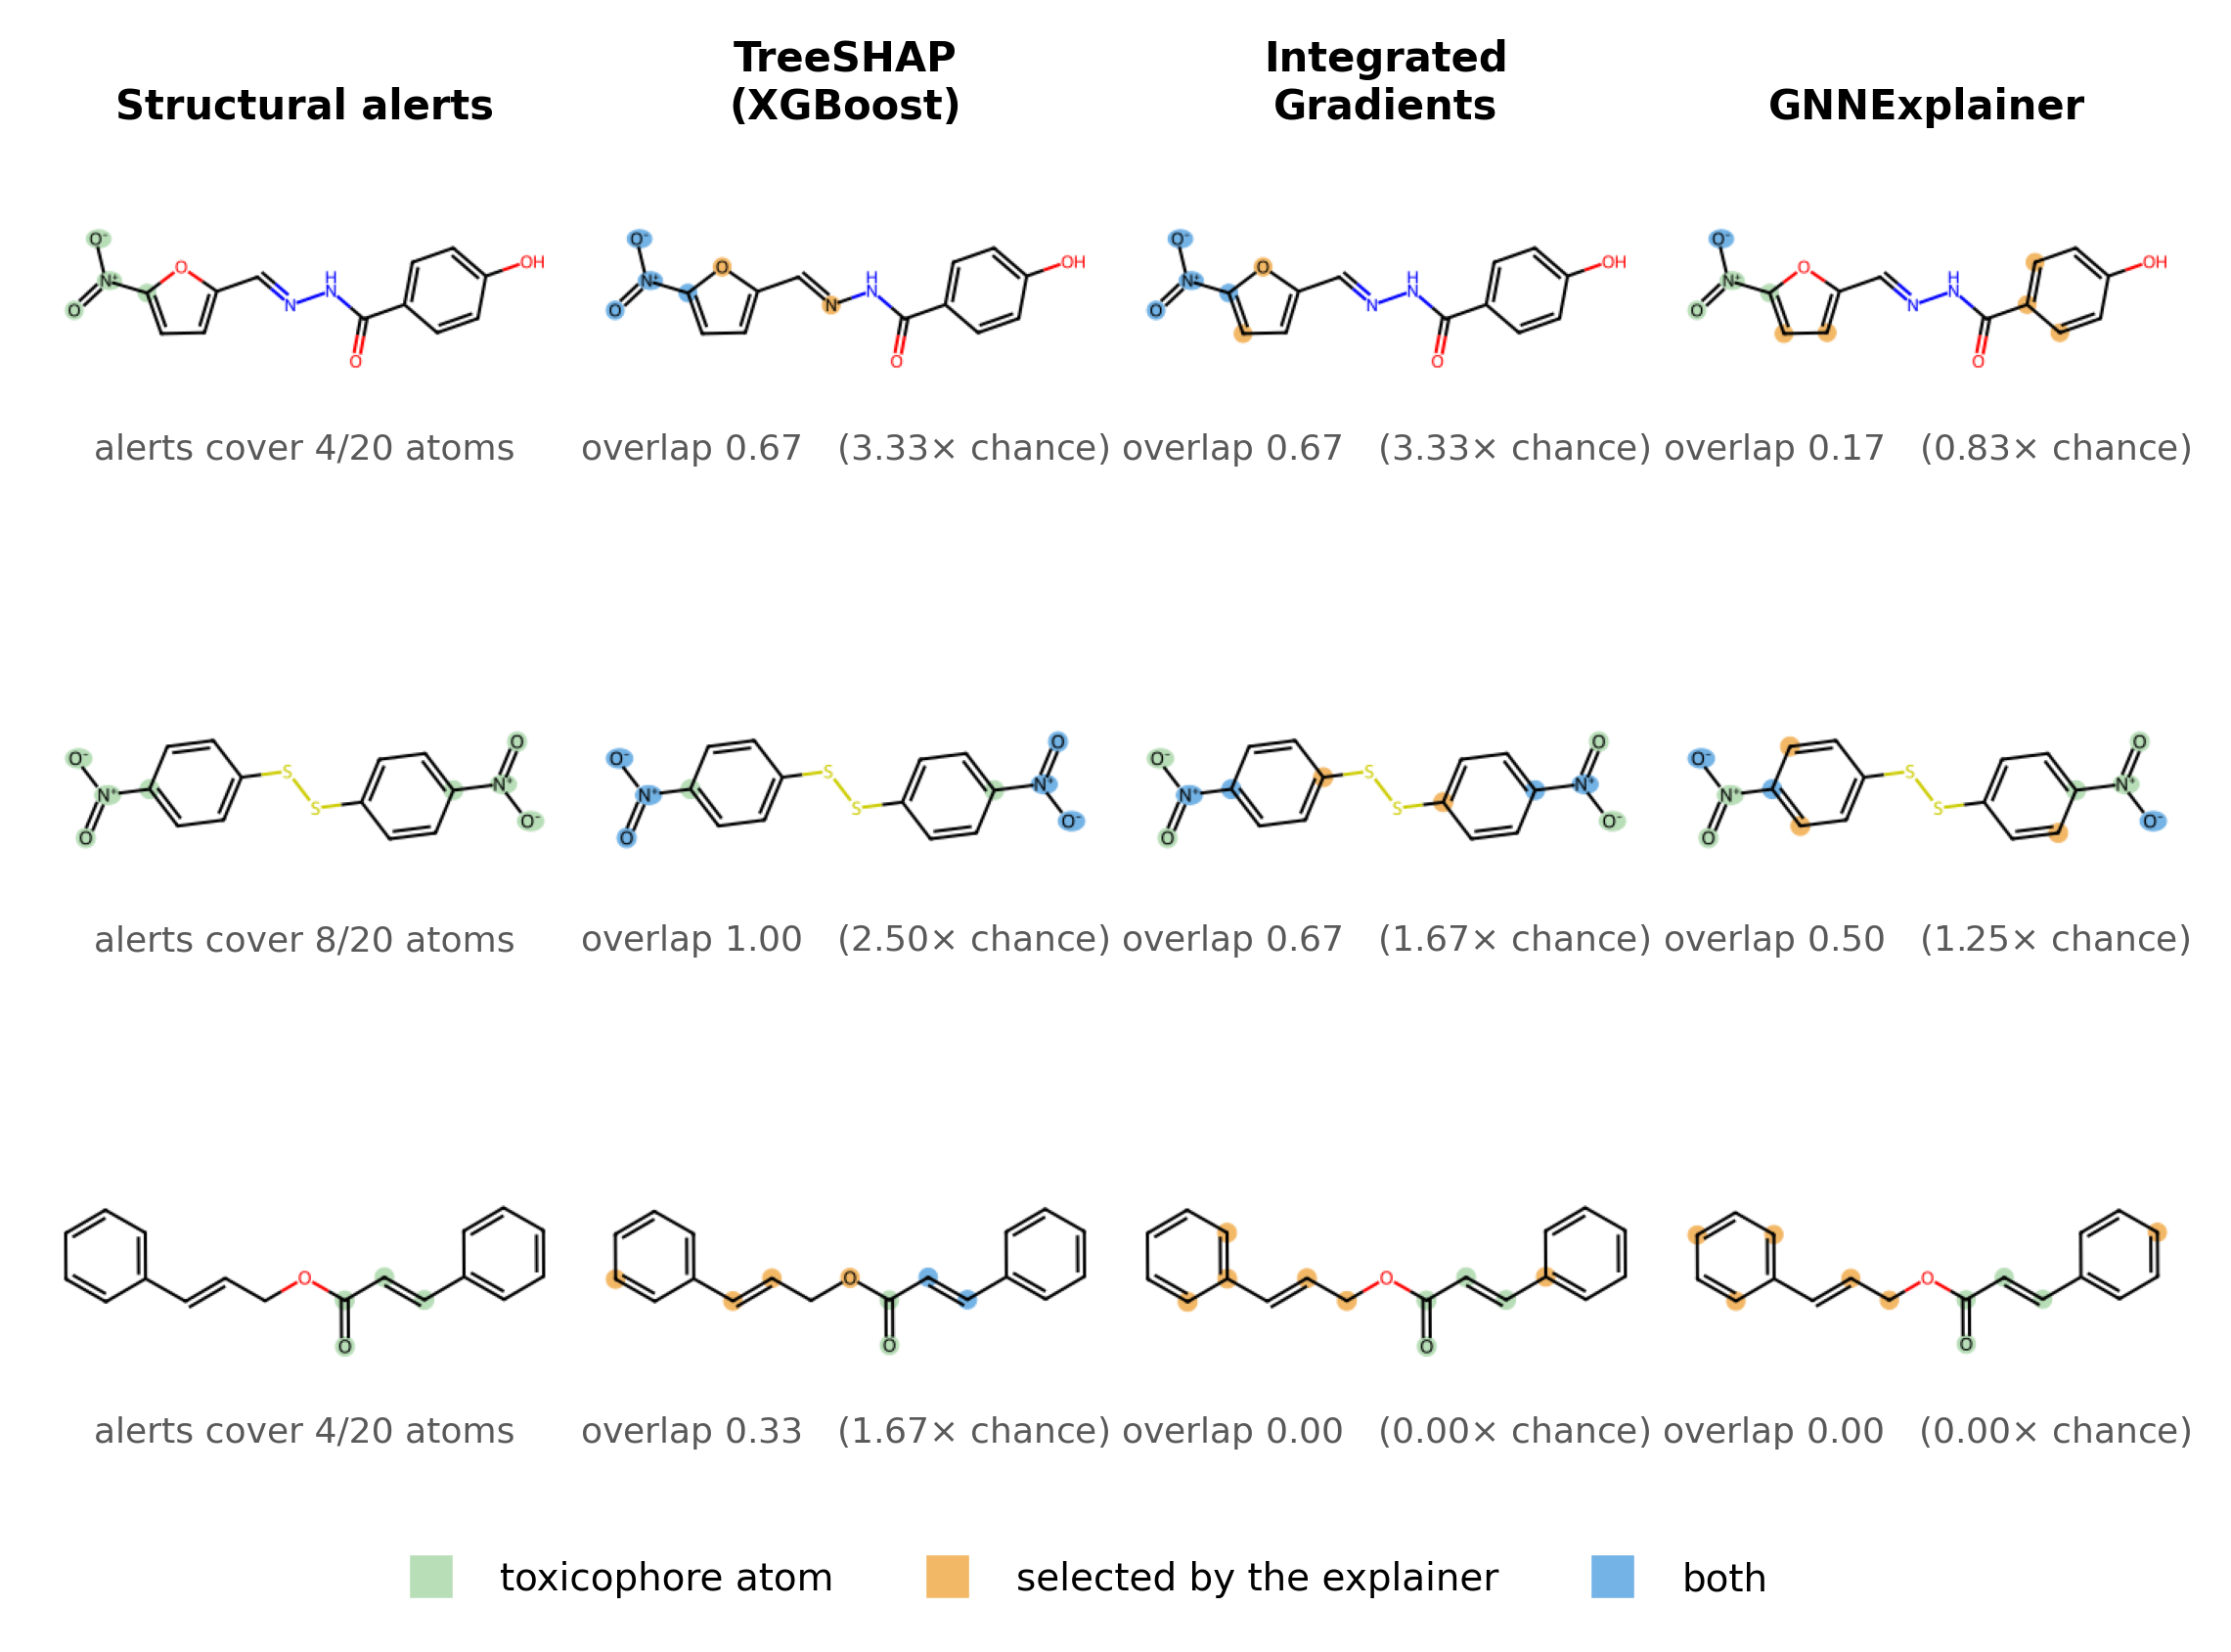

In [23]:
import fig_examples, importlib
importlib.reload(fig_examples)
chosen = fig_examples.build(R, FIGDIR, EVAL, SCORES, k_frac=K_FRAC)
print("molecules drawn (SMILES, share of atoms inside an alert):")
for smi, ch in chosen:
    print(f"  {ch:.2f}  {smi}")

from IPython.display import Image, display
display(Image(f"{FIGDIR}/fig13_examples.png", width=760))

## 8. Collecting the output

Everything the manuscript needs is gathered into a single archive: the figures in raster and
vector form, the LaTeX table fragments, the record of every quantity quoted in the text, and
the manifest describing which stage produced each result file.

In [24]:
import shutil, glob

STAGE = "/content/manuscript_assets"
shutil.rmtree(STAGE, ignore_errors=True)
os.makedirs(f"{STAGE}/figures", exist_ok=True)
os.makedirs(f"{STAGE}/tables", exist_ok=True)

for f in glob.glob(f"{FIGDIR}/*"):
    shutil.copy(f, f"{STAGE}/figures/")
for f in glob.glob(f"{TABDIR}/*"):
    shutil.copy(f, f"{STAGE}/tables/")
if os.path.exists(f"{R}/results_manifest.csv"):
    shutil.copy(f"{R}/results_manifest.csv", f"{STAGE}/tables/")

archive = shutil.make_archive("/content/manuscript_assets", "zip", STAGE)
size = os.path.getsize(archive) / 1e6
n_pdf = len(glob.glob(f"{STAGE}/figures/*.pdf"))
n_tex = len(glob.glob(f"{STAGE}/tables/*.tex"))
print(f"{n_pdf} figures, {n_tex} tables -> {archive} ({size:.1f} MB)")

from google.colab import files
files.download(archive)

13 figures, 14 tables -> /content/manuscript_assets.zip (3.0 MB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>